# Сбор и семантическое обогащение мест (POI) для рекомендаций — Москва

Тестовое задание на курсовую работу. В ноутбуке собран весь пайплайн, от сырых данных до поиска:

1. **Сбор датасета**: ~100 мест Москвы из OpenStreetMap, Википедии и Wikivoyage.
2. **Схема семантических признаков**: тип опыта, атмосфера, контекст, бюджет, время, популярность и др.
3. **Извлечение признаков**: правила по тегам OSM + словари по тексту + zero-shot на эмбеддингах + zero-shot NLI, сравнение на ручной разметке.
4. **EDA**: распределения категорий, атмосфер и контекстов, визуализации.
5. **Семантический поиск**: BM25 и dense-поиск по сырому тексту, по обогащённому тексту и гибрид с признаками; сравнение на 10 запросах.
6. **Выводы и ограничения**.

Все сетевые ответы кешируются в `data/raw/`, поэтому ноутбук перезапускается без интернета: в репозитории лежат уже скачанные данные.
Если удалить `data/raw/`, данные скачаются заново (тогда выборка может немного отличаться, потому что OSM и Википедия меняются).

**Запуск в Colab:**
```
!git clone https://git.miem.hse.ru/<user>/poi-recsys-test.git
%cd poi-recsys-test
!pip install -q -r requirements.txt
```

In [1]:
import os, re, json, time, math, random, difflib, collections
from pathlib import Path

import numpy as np
import pandas as pd
import requests

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
random.seed(42); np.random.seed(42)

DATA = Path('data'); RAW = DATA / 'raw'; RES = Path('results'); FIG = RES / 'figures'
for p in (RAW, FIG):
    p.mkdir(parents=True, exist_ok=True)

S = requests.Session()
# Wikimedia требует осмысленный User-Agent с контактом, иначе быстро отвечает 429
S.headers['User-Agent'] = 'hse-miem-student-poi-dataset/0.1 (educational project; https://git.miem.hse.ru) python-requests'


def cached_json(path, fetch):
    """Если файл уже есть, читаем его, иначе вызываем fetch() и сохраняем результат.
    Так ноутбук воспроизводим и лишний раз не нагружает публичные API."""
    path = Path(path)
    if path.exists():
        return json.loads(path.read_text('utf-8'))
    data = fetch()
    path.write_text(json.dumps(data, ensure_ascii=False), 'utf-8')
    return data


def get_json(url, params=None, tries=6):
    for i in range(tries):
        try:
            r = S.get(url, params=params, timeout=60)
            if r.status_code == 200 and r.text[:1] in '{[':
                return r.json()
            if r.status_code == 404:
                break
            wait = int(r.headers.get('Retry-After', 0) or 0)
        except requests.RequestException:
            wait = 0
        time.sleep(max(wait, 5 * 2 ** i))  # экспоненциальный backoff, на 429 смотрим Retry-After
    raise RuntimeError(f'не удалось получить {url}')

## Задание 1. Сбор датасета мест

### 1.1 Источники

| Источник | Что берём | Почему |
|---|---|---|
| **OpenStreetMap** (Overpass API) | название, тип объекта, координаты, адрес, часы работы, кухня, Wi-Fi, веранда, вегетарианское меню, платность входа, ссылки на Wikidata/Wikipedia | открытая лицензия ODbL, есть по всем типам мест, много структурированных тегов |
| **Википедия** (MediaWiki API) | вводная часть статьи (краткое описание) | качественный текст про музеи, парки, театры, достопримечательности |
| **Wikimedia Pageviews API** | число просмотров статьи за 12 месяцев | прокси **популярности** места |
| **Wikidata** | связь OSM → статья, число языковых версий | связывание источников, второй сигнал популярности |
| **Wikivoyage** (ru) | заметки путешественников о местах: что посмотреть, где поесть и выпить, цена, часы | самое близкое к **отзывам** из открытых источников: субъективный текст вроде «уютно», «дорого», «очередь» |

**Почему не Google Maps, 2ГИС, Яндекс, TripAdvisor.** Отзывы там есть, но их API требуют ключ и/или оплату (Google Places отдаёт до 5 отзывов на место, TripAdvisor Content API нужен ключ), а парсинг сайтов запрещён пользовательскими соглашениями.
Для тестового задания я решил ограничиться открытыми источниками с понятными лицензиями (ODbL, CC BY-SA).
Пайплайн устроен так, что отзывы потом добавляются как ещё одно текстовое поле (`traveler_note` или отдельное `reviews`), и дальше всё работает без изменений.

### 1.2 Город и категории
Город: **Москва** (граница `admin_level=4` в OSM). Категорий 10, чтобы покрыть основные сценарии гида: поесть, культура, прогулка, развлечения.

In [2]:
CITY = 'Москва'
QUOTAS = {               # максимум мест на категорию
    'кафе': 12, 'ресторан': 12, 'бар': 10,
    'музей': 12, 'галерея': 8, 'театр': 10,
    'парк': 12, 'достопримечательность': 12, 'храм': 6,
    'развлечения': 8,
}
FOOD = {'кафе', 'ресторан', 'бар'}
print('Целевой размер датасета:', sum(QUOTAS.values()))

Целевой размер датасета: 102


### 1.3 OpenStreetMap
Одним запросом к Overpass забираем все именованные объекты нужных типов в границах Москвы (административная граница `admin_level=4`). Храмы берём только со ссылкой на Википедию, иначе их тысячи.
Публичный `overpass-api.de` часто перегружен, поэтому перебираем зеркала.

In [3]:
OVERPASS_MIRRORS = [
    'https://overpass.private.coffee/api/interpreter',
    'https://overpass.kumi.systems/api/interpreter',
    'https://overpass-api.de/api/interpreter',
]
OVERPASS_QUERY = f'''[out:json][timeout:120];
area["name"="{CITY}"]["admin_level"="4"]->.a;
(
 nwr["amenity"~"^(cafe|restaurant|bar|pub|theatre|cinema)$"]["name"](area.a);
 nwr["tourism"~"^(museum|gallery|attraction|zoo|theme_park|viewpoint)$"]["name"](area.a);
 nwr["leisure"~"^(park|garden)$"]["name"](area.a);
 nwr["historic"~"^(monument|castle|manor)$"]["name"](area.a);
 nwr["amenity"="place_of_worship"]["name"]["wikipedia"](area.a);
);
out center tags;'''


def fetch_overpass():
    for url in OVERPASS_MIRRORS:
        for attempt in range(2):
            try:
                r = S.post(url, data={'data': OVERPASS_QUERY}, timeout=300)
                # зеркала иногда отвечают 200 с пустым списком (не готова база областей), такой ответ не принимаем
                if r.status_code == 200 and len(r.json().get('elements', [])) > 1000:
                    return r.json()
            except requests.RequestException:
                pass
            time.sleep(10)
    raise RuntimeError('все зеркала Overpass недоступны')


osm_raw = cached_json(RAW / 'osm_moscow.json', fetch_overpass)
print('Объектов OSM:', len(osm_raw['elements']), '| снимок данных:', osm_raw['osm3s']['timestamp_osm_base'])

Объектов OSM: 10900 | снимок данных: 2026-05-31T22:37:44Z


Сводим теги OSM к нашим 10 категориям. У объекта бывает несколько тегов (например, `tourism=museum` + `historic=manor`), поэтому проверяем по приоритету: сначала более конкретные типы, в конце общий `tourism=attraction`.

In [4]:
def osm_category(t):
    a, tour, lei, his = t.get('amenity'), t.get('tourism'), t.get('leisure'), t.get('historic')
    if a == 'cafe': return 'кафе'
    if a == 'restaurant': return 'ресторан'
    if a in ('bar', 'pub'): return 'бар'
    if tour == 'museum': return 'музей'
    if tour == 'gallery': return 'галерея'
    if a == 'theatre' and t.get('theatre:genre') in ('circus', 'philharmonic', 'concert'): return 'развлечения'
    if a == 'theatre': return 'театр'
    if tour in ('zoo', 'theme_park') or a == 'cinema': return 'развлечения'
    if lei in ('park', 'garden'): return 'парк'
    if a == 'place_of_worship': return 'храм'
    if tour in ('attraction', 'viewpoint') or his in ('monument', 'castle', 'manor'): return 'достопримечательность'
    return None


rows = []
for e in osm_raw['elements']:
    t = e.get('tags', {})
    cat = osm_category(t)
    if cat is None:
        continue
    lat = e.get('lat', e.get('center', {}).get('lat'))
    lon = e.get('lon', e.get('center', {}).get('lon'))
    rows.append({'osm_id': f"{e['type']}/{e['id']}", 'name': t['name'], 'category': cat,
                 'lat': lat, 'lon': lon, 'wikidata': t.get('wikidata'), 'wikipedia': t.get('wikipedia'),
                 'tags': t})
osm = pd.DataFrame(rows)
osm['n_tags'] = osm.tags.map(len)
print(osm.category.value_counts().to_string())

category
кафе                     4837
ресторан                 2645
бар                      1151
достопримечательность     600
парк                      536
музей                     367
театр                     249
развлечения               200
храм                      189
галерея                   126


### 1.4 Wikivoyage: заметки путешественников
Скачиваем wikitext всех статей «Москва/…» (по районам) и разбираем шаблоны `{{listing}}`, `{{see}}`, `{{eat}}`, `{{drink}}`, `{{do}}`.
В шаблоне есть название, описание, координаты, цена, часы работы и часто `wdid`, то есть идентификатор Wikidata. По нему запись надёжно связывается с OSM.

In [5]:
WV_API = 'https://ru.wikivoyage.org/w/api.php'


def fetch_wikivoyage():
    res = get_json(WV_API, dict(action='query', list='prefixsearch', pssearch=f'{CITY}/', pslimit=50, format='json'))
    titles = [p['title'] for p in res['query']['prefixsearch'] if p['title'].startswith(f'{CITY}/')] + [CITY]
    pages = {}
    for t in titles:
        d = get_json(WV_API, dict(action='parse', page=t, prop='wikitext', format='json'))
        pages[t] = d['parse']['wikitext']['*']
        time.sleep(1)
    return pages


wv_pages = cached_json(RAW / 'wikivoyage_moscow.json', fetch_wikivoyage)


def split_template_params(body):
    """Делим тело шаблона по '|' только на верхнем уровне: внутри [[ ]] и {{ }} тоже бывают '|'."""
    parts, depth, cur, i = [], 0, '', 0
    while i < len(body):
        two = body[i:i + 2]
        if two in ('{{', '[['): depth += 1; cur += two; i += 2; continue
        if two in ('}}', ']]'): depth -= 1; cur += two; i += 2; continue
        if body[i] == '|' and depth == 0: parts.append(cur); cur = ''; i += 1; continue
        cur += body[i]; i += 1
    parts.append(cur)
    return {k.strip(): v.strip() for k, v in (p.split('=', 1) for p in parts[1:] if '=' in p)}


def iter_listings(wikitext):
    for m in re.finditer(r'\{\{\s*(listing|see|do|eat|drink|buy|sleep)\s*[\n|]', wikitext):
        i = j = m.start(); depth = 0
        while j < len(wikitext):           # ищем парную закрывающую }}
            if wikitext[j:j + 2] == '{{': depth += 1; j += 2; continue
            if wikitext[j:j + 2] == '}}':
                depth -= 1; j += 2
                if depth == 0: break
                continue
            j += 1
        d = split_template_params(wikitext[i + 2:j - 2])
        d['type'] = d.get('type') or m.group(1)
        yield d


def clean_wikitext(s):
    s = re.sub(r'\{\{[^{}]*\}\}', '', s or '')            # вложенные шаблоны ({{Метро}}, {{Недоступная ссылка}}...)
    s = re.sub(r'\[\[(?:[^|\]]*\|)?([^\]]*)\]\]', r'\1', s)  # [[ссылка|текст]] → текст
    s = re.sub(r'\[https?://\S+\s*([^\]]*)\]', r'\1', s)     # [url текст] → текст
    s = re.sub(r"'{2,}", '', s)
    s = re.sub(r'<[^>]+>', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()


def to_float(x):
    try: return float(x)
    except (TypeError, ValueError): return np.nan


wv = pd.DataFrame([
    {'wv_type': d['type'], 'name': clean_wikitext(d.get('name')), 'note': clean_wikitext(d.get('description') or d.get('content')),
     'lat': to_float(d.get('lat')), 'lon': to_float(d.get('long')), 'price': clean_wikitext(d.get('price')),
     'hours': clean_wikitext(d.get('hours')), 'address': clean_wikitext(d.get('address')),
     'wikidata': (re.findall(r'Q\d+', d.get('wdid') or '') or [None])[0],   # бывает «Q4189954 <!--+Q4306169-->»
     'district': page.split('/', 1)[1] if '/' in page else None}
    for page, text in wv_pages.items() for d in iter_listings(text)
])
# статья «Москва/Аэропорт Шереметьево» описывает аэропорт в Химках, это уже не город Москва
wv = wv[(wv.name != '') & (wv.district != 'Аэропорт Шереметьево')].reset_index(drop=True)
print('Записей Wikivoyage:', len(wv), '| с описанием:', (wv.note.str.len() > 30).sum())
print(wv.groupby('wv_type').note.apply(lambda s: (s.str.len() > 30).sum()).to_string())

Записей Wikivoyage: 819 | с описанием: 368
wv_type
buy          19
do           59
drink         3
eat          21
go           20
listing       0
other         0
see         235
sleep        11
vicinity      0


### 1.5 Википедия и Wikidata
У значимых объектов в OSM обычно стоит тег `wikidata`. По нему через Wikidata API получаем:
- название статьи в русской Википедии;
- число языковых версий статьи (`sitelinks`), то есть насколько объект известен в мире.

In [6]:
def fetch_wikidata(qids):
    out = {}
    qids = sorted(set(qids))
    for i in range(0, len(qids), 50):
        d = get_json('https://www.wikidata.org/w/api.php',
                     dict(action='wbgetentities', ids='|'.join(qids[i:i + 50]), props='sitelinks', format='json'))
        for q, ent in d.get('entities', {}).items():
            sl = ent.get('sitelinks', {})
            out[q] = {'ruwiki': sl.get('ruwiki', {}).get('title'),
                      'n_sitelinks': sum(k.endswith('wiki') and k != 'commonswiki' for k in sl)}
        time.sleep(0.5)
    return out


non_food_qids = osm.loc[~osm.category.isin(FOOD) & osm.wikidata.notna(), 'wikidata'].str.split(';').str[0]
all_qids = set(non_food_qids) | set(wv.wikidata.dropna())
wikidata = cached_json(RAW / 'wikidata.json', lambda: fetch_wikidata(all_qids))
print('Сущностей Wikidata:', len(wikidata))

Сущностей Wikidata: 879


### 1.6 Отбор мест: как выбирались и какие ограничения применены

**Некулинарные категории** (музей, галерея, театр, парк, достопримечательность, храм, развлечения):
1. Берём только объекты, у которых есть статья в русской Википедии: без текста описания признаки не извлечь.
2. Убираем дубли: один объект Wikidata часто нарисован в OSM несколько раз (здание + территория).
3. Предварительно берём топ-`3×квота` по числу языковых версий, чтобы не запрашивать просмотры для тысячи статей.
4. Для них загружаем вводную часть статьи и просмотры за последние 12 месяцев.
5. Итог: топ-`квота` по просмотрам при длине описания ≥ 200 символов.

Такой отбор специально смещён к **известным** местам, ведь в первую очередь их и спрашивают у гида. Это ограничение я разбираю в конце.

**Кафе, рестораны, бары.** Статей в Википедии у них почти нет (в OSM на ~8 тыс. заведений около 7 со ссылкой на Википедию), поэтому:
1. Сначала берём все заведения из Wikivoyage с непустым описанием: их отобрал живой человек, и текст субъективный, «отзывный».
2. Остаток квоты добираем из OSM: **не сетевые** (нет тега `brand`, а название встречается в OSM меньше 3 раз), с часами работы и кухней, по убыванию «полноты» тегов (Wi-Fi, веранда, вегетарианское меню, курение и т.д.). Чем больше тегов, тем больше признаков можно извлечь.
3. Для таких заведений описание собираем из тегов в шаблонный текст. Это слабое место датасета, и потом посмотрим, как оно влияет на поиск.

In [7]:
PV_START, PV_END = '2025100100', '2026093000'   # последние 12 полных месяцев


def fetch_pageviews(title):
    t = title.replace(' ', '_')
    url = (f'https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/ru.wikipedia/all-access/user/'
           f'{requests.utils.quote(t, safe="")}/monthly/{PV_START}/{PV_END}')
    try:
        return sum(i['views'] for i in get_json(url, tries=2)['items'])
    except RuntimeError:
        return 0


def fetch_extracts(titles):
    out = {}
    titles = list(titles)
    for i in range(0, len(titles), 20):     # API отдаёт extracts максимум для 20 статей за раз
        d = get_json('https://ru.wikipedia.org/w/api.php',
                     dict(action='query', prop='extracts', exintro=1, explaintext=1, exlimit=20, redirects=1,
                          titles='|'.join(titles[i:i + 20]), format='json'))
        norm = {x['from']: x['to'] for x in d['query'].get('normalized', []) + d['query'].get('redirects', [])}
        by_title = {p['title']: p.get('extract', '') for p in d['query']['pages'].values()}
        for t in titles[i:i + 20]:
            final = norm.get(norm.get(t, t), norm.get(t, t))   # цепочка: нормализация → редирект
            out[t] = {'title': final, 'extract': by_title.get(final, '')}
        time.sleep(0.5)
    return out


def top_per_category(df, by, mult=1):
    """Первые mult×квота строк в каждой категории по убыванию столбца by."""
    df = df.sort_values(by, ascending=False)
    return df[df.groupby('category').cumcount() < df.category.map(QUOTAS) * mult]


cand = osm[~osm.category.isin(FOOD) & osm.wikidata.notna()].copy()
cand['wikidata'] = cand.wikidata.str.split(';').str[0]
cand['ruwiki'] = cand.wikidata.map(lambda q: wikidata.get(q, {}).get('ruwiki'))
cand['n_sitelinks'] = cand.wikidata.map(lambda q: wikidata.get(q, {}).get('n_sitelinks', 0))
cand = (cand.dropna(subset=['ruwiki'])
            .sort_values('n_tags', ascending=False)          # из дублей оставляем самый подробно размеченный
            .drop_duplicates('wikidata').drop_duplicates('ruwiki'))
pre = top_per_category(cand, 'n_sitelinks', mult=3).copy()
print('Кандидатов после предотбора:', len(pre))

extracts = cached_json(RAW / 'wiki_extracts.json', lambda: fetch_extracts(pre.ruwiki))
pre['ruwiki'] = pre.ruwiki.map(lambda t: extracts[t]['title'])      # название после редиректов
# в Википедии стоят знаки ударения («Вы́ставка»), они ломают поиск по словам, поэтому убираем
pre['description'] = (pre.ruwiki.map({v['title']: v['extract'] for v in extracts.values()}).fillna('')
                         .str.replace('\u0301', '', regex=False).str.replace(r'\s+', ' ', regex=True).str.strip())
# просмотры считаем по итоговому названию, иначе у статей-редиректов получится почти 0
pageviews = cached_json(RAW / 'wiki_pageviews.json', lambda: {t: fetch_pageviews(t) for t in pre.ruwiki.unique()})
pre['pageviews_12m'] = pre.ruwiki.map(pageviews).fillna(0).astype(int)
pre = pre[pre.description.str.len() >= 200]

# Проверка связи OSM → Википедия. В OSM тег wikidata иногда указывает на «предмет» объекта, а не на сам объект:
# «Музей Отечественной войны 1812 года» → статья о войне, «Мемориальная усадьба Шаляпина» → статья о Шаляпине.
# Отбрасываем статьи о людях (формат «Фамилия, Имя») и статьи, где во вступлении нет слова, подходящего к категории.
CATEGORY_HINTS = {
    'музей': r'музе|выстав|экспозиц|палат|дворец', 'галерея': r'галере|музе|искусств|выстав', 'театр': r'театр',
    'парк': r'парк|сад|усадьб|заповедн|лес|пруд|выставк|пространств',
    'храм': r'храм|собор|церк|монастыр|колокольн|мечет|синагог',
    'развлечения': r'зоопарк|кинотеатр|цирк|аттракцион|аквапарк|развлекат|концерт', 'достопримечательность': r'.',
}
is_person = pre.ruwiki.str.contains(r'^[^,(]+, [А-ЯЁ]', regex=True)
hint_ok = pre.apply(lambda r: bool(re.search(CATEGORY_HINTS[r.category], r.description[:400].lower())), axis=1)
print('Отброшено как неверная связь:', pre.loc[is_person | ~hint_ok, 'name'].tolist())
pre = pre[~is_person & hint_ok]
sel_nonfood = top_per_category(pre, 'pageviews_12m').copy()
sel_nonfood['source'] = 'osm+wikipedia'
print(sel_nonfood.category.value_counts().to_string())

Кандидатов после предотбора: 175
Отброшено как неверная связь: ['Музей Отечественной войны 1812 года', 'Мемориальная усадьба Ф. И. Шаляпина', 'Нехорошая квартира', 'Московский музей современного искусства']
category
достопримечательность    12
музей                    12
парк                     12
театр                    10
развлечения               7
храм                      6
галерея                   6


Подтягиваем заметки Wikivoyage к выбранным объектам по `wikidata`: это второй, более «человеческий» текст.

In [8]:
wv_by_qid = (wv[wv.note.str.len() > 30].dropna(subset=['wikidata'])
             .drop_duplicates('wikidata').set_index('wikidata'))
for col in ('note', 'price', 'hours', 'district', 'address'):
    sel_nonfood['wv_' + col] = sel_nonfood.wikidata.map(wv_by_qid[col])
print('Найдена заметка Wikivoyage для', sel_nonfood.wv_note.notna().sum(), 'из', len(sel_nonfood))

Найдена заметка Wikivoyage для 25 из 65


### 1.7 Кафе, рестораны, бары
**Шаг 1.** Заведения из Wikivoyage сопоставляем с OSM: ближайшая точка общепита в радиусе 150 м с похожим названием.
Если пара нашлась, берём из OSM категорию и теги. Если нет, категорию определяем по словам в названии и описании.

In [9]:
def norm_name(s):
    s = s.lower().replace('ё', 'е')
    s = re.sub(r'(кафе|ресторан|бар|паб|кофейня|«|»|"|\'|на [а-я]+ой)', ' ', s)
    return re.sub(r'[^a-zа-я0-9]+', ' ', s).strip()


def haversine_m(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2 +
         np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 2 * 6371000 * np.arcsin(np.sqrt(a))


osm_food = osm[osm.category.isin(FOOD)].reset_index(drop=True)


def match_food(r):
    if np.isnan(r.lat):
        return None
    dist = haversine_m(r.lat, r.lon, osm_food.lat.values, osm_food.lon.values)
    best, best_score = None, 0
    for i in np.where(dist < 150)[0]:
        sim = difflib.SequenceMatcher(None, norm_name(r['name']), norm_name(osm_food.at[i, 'name'])).ratio()
        if sim > 0.6 and sim > best_score:
            best, best_score = i, sim
    return best


def guess_food_category(name, note):
    # сначала смотрим на название («Ресторан …», «Столовая …»), и только если по нему непонятно, на описание
    for t in (name.lower(), note.lower()):
        if re.search(r'ресторан|корчма|трактир', t): return 'ресторан'
        if re.search(r'\b(бар|паб|пивн|рюмочн|коктейл|pub|bar)', t): return 'бар'
        if re.search(r'кофе|кафе|пекарн|кондитер|чайн|блинн|пельменн|столов|буфет|coffee|выпечк', t): return 'кафе'
    return 'ресторан'


wv_food = wv[wv.wv_type.isin(['eat', 'drink']) & (wv.note.str.len() > 30)
             & ~wv.name.str.contains('Комплекс заведений')].drop_duplicates('name').copy()
wv_food['osm_idx'] = wv_food.apply(match_food, axis=1)
food_rows = []
for _, r in wv_food.iterrows():
    o = osm_food.loc[int(r.osm_idx)] if pd.notna(r.osm_idx) else None
    food_rows.append({
        'osm_id': o.osm_id if o is not None else None, 'name': r['name'],
        'category': o.category if o is not None else guess_food_category(r['name'], r.note),
        'lat': r.lat, 'lon': r.lon, 'tags': o.tags if o is not None else {}, 'wikidata': r.wikidata,
        'wv_note': r.note, 'wv_price': r.price, 'wv_hours': r.hours, 'wv_district': r.district, 'wv_address': r.address,
        'source': 'wikivoyage' + ('+osm' if o is not None else '')})
food_wv = pd.DataFrame(food_rows)
print('Заведений из Wikivoyage:', len(food_wv), '| сопоставлено с OSM:', food_wv.osm_id.notna().sum())
print(food_wv.category.value_counts().to_string())

Заведений из Wikivoyage: 23 | сопоставлено с OSM: 9
category
ресторан    14
кафе         6
бар          3


**Шаг 2.** Добираем квоту из OSM по «полноте» тегов.

In [10]:
INFO_TAGS = ['outdoor_seating', 'internet_access', 'diet:vegetarian', 'diet:vegan', 'wheelchair', 'smoking',
             'takeaway', 'delivery', 'air_conditioning', 'indoor_seating', 'description', 'website',
             'contact:website', 'capacity', 'microbrewery', 'craft_beer', 'drink:coffee', 'payment:credit_cards']


def tag_richness(t):
    return sum(k in t for k in INFO_TAGS)


# сеть = нет тега brand, но одно и то же название встречается в OSM 3+ раз (Stars Coffee, Наф-Наф…)
name_counts = osm_food.name.str.lower().value_counts()
pool = osm_food[osm_food.tags.map(lambda t: 'brand' not in t and 'brand:wikidata' not in t
                                  and 'opening_hours' in t and 'cuisine' in t and 'addr:street' in t)
                & (osm_food.name.str.lower().map(name_counts) < 3)].copy()
pool['richness'] = pool.tags.map(tag_richness)
pool = pool[~pool.osm_id.isin(food_wv.osm_id.dropna())].drop_duplicates('name')
pool = pool.sample(frac=1, random_state=42).sort_values('richness', ascending=False, kind='stable')

parts = []
for cat in FOOD:
    have = food_wv[food_wv.category == cat].head(QUOTAS[cat])
    need = QUOTAS[cat] - len(have)
    extra = pool[pool.category == cat].head(max(need, 0)).assign(source='osm')
    parts += [have, extra]
sel_food = pd.concat(parts, ignore_index=True)
print(sel_food.groupby(['category', 'source']).size().to_string())

category  source        
бар       osm               7
          wikivoyage        2
          wikivoyage+osm    1
кафе      osm               6
          wikivoyage        4
          wikivoyage+osm    2
ресторан  wikivoyage        6
          wikivoyage+osm    6


### 1.8 Развлечения: добор из Wikivoyage
У кинотеатров, цирков и аквапарков статей в Википедии мало, поэтому по Википедии нашлось всего несколько «развлечений».
Добираем квоту из записей Wikivoyage типа `do`/`see` по ключевым словам. Описанием тогда служит заметка путешественника.

In [11]:
FUN_RE = r'кинотеатр|кино\b|цирк|аквапарк|боулинг|концерт|зоопарк|аттракцион|бани\b|каток|квест|синема'
need_fun = QUOTAS['развлечения'] - (sel_nonfood.category == 'развлечения').sum()
fun = wv[wv.wv_type.isin(['do', 'see']) & (wv.note.str.len() > 25) & wv.lat.notna()
         & (wv.name + ' ' + wv.note.str[:60]).str.lower().str.contains(FUN_RE)
         & ~wv.name.isin(sel_nonfood.name) & ~wv.wikidata.isin(sel_nonfood.wikidata.dropna())
         & ~wv.name.str.lower().str.contains('музе|театр|галере')].drop_duplicates('name')
fun = fun.head(max(need_fun, 0))
sel_fun = pd.DataFrame({'name': fun.name, 'category': 'развлечения', 'lat': fun.lat, 'lon': fun.lon,
                        'wikidata': fun.wikidata, 'wv_note': fun.note, 'wv_price': fun.price, 'wv_hours': fun.hours,
                        'wv_district': fun.district, 'wv_address': fun.address, 'tags': [{}] * len(fun),
                        'source': 'wikivoyage'})
print(sel_fun[['name', 'wv_district']].to_string())

                  name    wv_district
60  Кожевнические бани  Замоскворечье


### 1.9 Сборка итоговой таблицы
Приводим все три ветки (OSM+Википедия, общепит, развлечения из Wikivoyage) к одной схеме:

| поле | смысл |
|---|---|
| `name`, `category`, `city`, `district`, `address`, `lat`, `lon` | идентификация и геопозиция |
| `description` | «объективное» описание: вступление статьи Википедии **или** текст, собранный из тегов OSM |
| `traveler_note` | заметка путешественника из Wikivoyage, наш аналог **отзыва** |
| `opening_hours`, `price_text` | часы работы (OSM / Wikivoyage) и цена (Wikivoyage) |
| `pageviews_12m`, `n_sitelinks` | сигналы популярности (только для мест со статьёй в Википедии) |
| `osm_tags` | полезные структурированные теги OSM (Wi-Fi, веранда, кухня, платность…) |

Для заведений без статьи в Википедии описание генерируется из тегов OSM шаблоном вроде «Кафе «X». Кухня: кофе, выпечка. Есть Wi-Fi…».

In [12]:
CUISINE_RU = {
    'coffee_shop': 'кофе', 'coffee': 'кофе', 'italian': 'итальянская', 'georgian': 'грузинская', 'russian': 'русская',
    'japanese': 'японская', 'sushi': 'суши', 'pizza': 'пицца', 'burger': 'бургеры', 'asian': 'азиатская',
    'european': 'европейская', 'french': 'французская', 'american': 'американская', 'chinese': 'китайская',
    'uzbek': 'узбекская', 'caucasian': 'кавказская', 'regional': 'региональная', 'international': 'интернациональная',
    'cake': 'торты', 'dessert': 'десерты', 'breakfast': 'завтраки', 'pastry': 'выпечка', 'bakery': 'выпечка',
    'sandwich': 'сэндвичи', 'steak_house': 'стейки', 'seafood': 'морепродукты', 'vegetarian': 'вегетарианская',
    'beer': 'пиво', 'wine': 'вино', 'mexican': 'мексиканская', 'indian': 'индийская', 'thai': 'тайская',
    'vietnamese': 'вьетнамская', 'korean': 'корейская', 'spanish': 'испанская', 'mediterranean': 'средиземноморская',
    'tea': 'чай', 'ice_cream': 'мороженое', 'pancake': 'блины', 'crepe': 'блины', 'grill': 'гриль',
    'cocktail': 'коктейли', 'pub': 'паб', 'irish': 'ирландская', 'british': 'британская', 'czech': 'чешская',
    'german': 'немецкая', 'ukrainian': 'украинская', 'bulgarian': 'болгарская', 'turkish': 'турецкая',
    'argentinian': 'аргентинская', 'donut': 'пончики', 'soup': 'супы', 'snack': 'закуски', 'kebab': 'шашлык',
}
USEFUL_TAGS = ['cuisine', 'opening_hours', 'outdoor_seating', 'internet_access', 'internet_access:fee', 'diet:vegetarian',
               'diet:vegan', 'smoking', 'takeaway', 'delivery', 'wheelchair', 'craft_beer', 'microbrewery', 'capacity',
               'fee', 'charge', 'theatre:genre', 'museum', 'description']


def describe_from_tags(cat, name, t):
    noun = {'кафе': 'Кафе', 'ресторан': 'Ресторан', 'бар': 'Бар'}.get(cat, cat.capitalize())
    title = name if re.search(r'[«"]', name) else f'«{name}»'
    # «Кафе «Сорока»», «Столовая № 57»: тип уже есть в названии, второй раз не добавляем
    has_type = re.match(r'(кафе|ресторан|бар|столовая|чебуречная|корчма|вареничная|спецбуфет|клуб|кофейня)', name.lower())
    parts = [(name if has_type else f'{noun} {title}') + '.']
    if t.get('description') and t['description'].lower() != name.lower():
        parts.append(t['description'].rstrip('.') + '.')
    if t.get('cuisine'):
        cs = [CUISINE_RU.get(c.strip(), c.strip().replace('_', ' ')) for c in t['cuisine'].split(';')]
        parts.append('Кухня: ' + ', '.join(dict.fromkeys(cs)) + '.')
    if t.get('outdoor_seating') == 'yes': parts.append('Есть летняя веранда.')
    if t.get('internet_access') in ('wlan', 'yes', 'wifi'):
        parts.append('Есть Wi-Fi' + (' (бесплатный)' if t.get('internet_access:fee') == 'no' else '') + '.')
    if t.get('diet:vegan') in ('yes', 'only'): parts.append('Есть веганское меню.')
    elif t.get('diet:vegetarian') in ('yes', 'only'): parts.append('Есть вегетарианские блюда.')
    if t.get('smoking') == 'no': parts.append('Курить нельзя.')
    elif t.get('smoking') in ('yes', 'outside', 'isolated', 'separated'): parts.append('Есть зона для курения.')
    if t.get('craft_beer') == 'yes' or t.get('microbrewery') == 'yes': parts.append('Крафтовое пиво.')
    if t.get('takeaway') == 'yes': parts.append('Можно взять с собой.')
    if t.get('delivery') == 'yes': parts.append('Есть доставка.')
    if t.get('capacity'): parts.append(f"Мест: {t['capacity']}.")
    if t.get('wheelchair') == 'yes': parts.append('Доступно для колясок.')
    if t.get('opening_hours'): parts.append(f"Часы работы: {t['opening_hours']}.")
    return ' '.join(parts)


def trim_text(s, n=1200):
    """Обрезаем длинные вступления Википедии по границе предложения."""
    s = (s or '').strip()
    if len(s) <= n:
        return s
    cut = s[:n]
    return cut[:cut.rfind('. ') + 1] or cut


def address_from(t, fallback=''):
    if t.get('addr:street'):
        return f"{t['addr:street']}, {t.get('addr:housenumber', '')}".strip(', ')
    return fallback or ''


common = ['name', 'category', 'lat', 'lon', 'wikidata', 'tags', 'source',
          'wv_note', 'wv_price', 'wv_hours', 'wv_district', 'wv_address']
nonfood = sel_nonfood.assign(wikipedia_title=sel_nonfood.ruwiki)[common + ['osm_id', 'description', 'pageviews_12m',
                                                                           'n_sitelinks', 'wikipedia_title']]
places = pd.concat([nonfood, sel_food, sel_fun], ignore_index=True)
places['tags'] = places.tags.map(lambda t: t if isinstance(t, dict) else {})
places['description'] = [
    trim_text(d) if isinstance(d, str) and d else describe_from_tags(c, n, t)
    for d, c, n, t in zip(places.description, places.category, places.name, places.tags)]
places['traveler_note'] = places.wv_note.fillna('')
places['opening_hours'] = [t.get('opening_hours') or (h if isinstance(h, str) else '') for t, h in zip(places.tags, places.wv_hours)]
places['price_text'] = places.wv_price.fillna('')
places['address'] = [address_from(t, a if isinstance(a, str) else '') for t, a in zip(places.tags, places.wv_address)]
places['osm_tags'] = places.tags.map(lambda t: {k: t[k] for k in USEFUL_TAGS if k in t})
places['city'] = CITY

# Район (по делению Wikivoyage): берём из заметки, иначе по ближайшей записи Wikivoyage в радиусе 2 км.
wv_geo = wv.dropna(subset=['lat', 'district'])


def nearest_district(lat, lon):
    d = haversine_m(lat, lon, wv_geo.lat.values, wv_geo.lon.values)
    return wv_geo.district.values[d.argmin()] if d.min() < 2000 else 'другой'


places['district'] = [d if isinstance(d, str) and d else nearest_district(la, lo)
                      for d, la, lo in zip(places.wv_district, places.lat, places.lon)]
for col in ('name', 'description', 'traveler_note', 'address', 'price_text', 'opening_hours'):
    places[col] = places[col].fillna('').str.replace('\xa0', ' ').str.replace(r'\s+', ' ', regex=True).str.strip()
places = places.drop_duplicates('name').reset_index(drop=True)
places.insert(0, 'place_id', [f'p{i:03d}' for i in range(len(places))])
places = places[['place_id', 'name', 'category', 'city', 'district', 'address', 'lat', 'lon', 'description',
                 'traveler_note', 'opening_hours', 'price_text', 'pageviews_12m', 'n_sitelinks', 'wikipedia_title',
                 'wikidata', 'osm_id', 'source', 'osm_tags']]
print('Итого мест:', len(places))
places.category.value_counts().to_frame('мест')

Итого мест: 100


,мест
category,
достопримечательность,12
музей,12
парк,12
ресторан,12
кафе,12
театр,10
бар,10
развлечения,8
храм,6


Заполненность полей. Видно, где датасет «тонкий».

In [13]:
fill = pd.DataFrame({
    'описание ≥ 200 симв.': places.description.str.len() >= 200,
    'заметка путешественника': places.traveler_note.str.len() > 0,
    'часы работы': places.opening_hours.str.len() > 0,
    'цена': places.price_text.str.len() > 0,
    'адрес': places.address.str.len() > 0,
    'просмотры Википедии': places.pageviews_12m.notna(),
}).groupby(places.category).mean().round(2)
fill

,описание ≥ 200 симв.,заметка путешественника,часы работы,цена,адрес,просмотры Википедии
category,,,,,,
бар,0.00,0.30,0.90,0.00,1.00,0.00
галерея,1.00,0.00,0.67,0.00,0.67,1.00
достопримечательность,1.00,0.58,0.25,0.17,0.33,1.00
кафе,0.00,0.50,0.75,0.33,0.92,0.00
музей,1.00,0.42,0.50,0.33,0.75,1.00
парк,1.00,0.33,0.33,0.08,0.17,1.00
развлечения,0.88,0.25,0.38,0.00,0.62,0.88
ресторан,0.00,1.00,0.58,0.58,0.92,0.00
театр,1.00,0.20,0.60,0.00,0.90,1.00


In [14]:
places.to_json(DATA / 'places.json', orient='records', force_ascii=False, indent=1)
places.drop(columns='osm_tags').to_csv(DATA / 'places.csv', index=False)
places.sample(5, random_state=1)[['name', 'category', 'district', 'description', 'traveler_note']]

,name,category,district,description,traveler_note
80,Спецбуфет № 1,кафе,Кремль и Китай-город,Спецбуфет № 1.,"От американского дайнера здесь интерьер, а от советской столовой — всё остальное, в том числе и качество обслуживани..."
84,Boring Coffee,кафе,Поклонная гора и Дорогомилово,Кафе «Boring Coffee». Кухня: кофе. Есть Wi-Fi. Курить нельзя. Можно взять с собой. Доступно для колясок. Часы работы...,
33,Парк Воробьёвы горы,парк,Хамовники,"Воробьёвы горы (в 1935—1999 годах — Ленинские горы) — название местности на юго-западе Москвы, представляющей собой ...",
81,Krispy Kreme Doughnuts,кафе,Кремль и Китай-город,Кафе «Krispy Kreme Doughnuts».,"Кафе практически на Красной площади, относится к малоизвестной в России сети, специализирующейся на выпечке пончиков..."
93,1980,бар,другой,"Бар «1980». Ресторанный Бар Клуба 1980. Кухня: бургеры, friture, chicken, кофе, pasta, русская, fish and chips, сэнд...",


### 1.10 Итоги по заданию 1

- **Как выбирались места.** Некулинарные: объекты OSM со статьёй в русской Википедии, топ по просмотрам за 12 месяцев внутри категории, с проверкой корректности связи OSM → статья. Общепит: заведения из Wikivoyage (их отобрали авторы путеводителя), затем несетевые заведения OSM с самой полной разметкой тегами.
- **Категории (10):** кафе, ресторан, бар, музей, галерея, театр, парк, достопримечательность, храм, развлечения.
- **Источники:** OpenStreetMap (Overpass), Википедия + Pageviews API, Wikidata, Wikivoyage.
- **Ограничения по количеству:** квоты от 6 до 12 мест на категорию (`QUOTAS`), чтобы крупные категории (в OSM около 4800 кафе) не забили мелкие (около 130 галерей). Храмов всего 6, чтобы кремлёвские соборы не заняли половину датасета. Галерей набралось 6 из 8: остальные кандидаты отсеялись из-за коротких статей.
- **Отзывы.** Настоящих пользовательских отзывов в открытом доступе с подходящей лицензией нет, поэтому их роль играют заметки путешественников из Wikivoyage. Они есть у ~40% мест.

## Задание 2. Семантические признаки

Я исходил из того, как пользователь формулирует запрос гиду: *«куда сходить **вечером** **с девушкой**, чтобы было **недорого** и **уютно**»*.
В запросе есть **что** (тип опыта), **как** (атмосфера), **с кем** (контекст), **когда** (время) и **сколько стоит** (бюджет).
Все эти оси я и сделал признаками. Кроме них добавил несколько практических признаков, которые часто решают выбор.

| Признак | Значения | Тип | Зачем для рекомендаций |
|---|---|---|---|
| `experience` | еда, культура и искусство, история, архитектура, природа и прогулки, развлечения и шоу, ночная жизнь, религия | multi-label | основной фильтр по намерению («хочу погулять» ≠ «хочу поесть»); категория OSM слишком узкая: музей-заповедник = история + прогулка |
| `atmosphere` | уютная, романтичная, шумная, спокойная, торжественная, историческая, современная | multi-label | различает места внутри одной категории: шумный паб и тихая кофейня оба «бар/кафе» |
| `context` | с детьми, с друзьями, свидание, работа и учёба, в одиночку, туристам | multi-label | прямо отвечает на «с кем», самую частую часть разговорного запроса |
| `budget` | бесплатно, низкий, средний, высокий | single | жёсткое ограничение пользователя, по нему удобно фильтровать |
| `time_of_day` | утро, день, вечер, ночь | multi-label | «куда пойти вечером»: место должно быть открыто и уместно в это время |
| `popularity` | высокая, средняя, низкая, неизвестно (+ число `pageviews_12m`) | single + число | смешивать известное с «нишевым», решать холодный старт; туристам важнее топ |
| `indoor_outdoor` | в помещении, на открытом воздухе, смешанный | single | погода и сезон: зимой и в дождь не советуем парк |
| `visit_duration` | до 1 ч, 1–2 ч, 2–3 ч, полдня | single | планирование маршрута в conversational-гиде |
| `has_wifi`, `has_terrace`, `veg_friendly`, `wheelchair` | bool | bool | частые уточнения: «с Wi-Fi», «с верандой», «вегетарианское», доступность |

Признаки делятся на две группы, и извлекаются они по-разному (задание 3):
- **структурные** (`budget`, `time_of_day`, `popularity`, `indoor_outdoor`, `visit_duration`, флаги удобств): их надёжнее брать из полей и тегов (цена, часы работы, `outdoor_seating`, просмотры), чем угадывать по тексту;
- **«мягкие» семантические** (`experience`, `atmosphere`, `context`): их надо вытаскивать из текста, и тут нужны NLP-модели.

In [15]:
EXPERIENCE = ['еда', 'культура и искусство', 'история', 'архитектура', 'природа и прогулки',
              'развлечения и шоу', 'ночная жизнь', 'религия']
ATMOSPHERE = ['уютная', 'романтичная', 'шумная', 'спокойная', 'торжественная', 'историческая', 'современная']
CONTEXT = ['с детьми', 'с друзьями', 'свидание', 'работа и учёба', 'в одиночку', 'туристам']
GROUPS = {'experience': EXPERIENCE, 'atmosphere': ATMOSPHERE, 'context': CONTEXT}

## Задание 3. Извлечение признаков

### 3.0 Подход
Я сравнил три способа извлекать «мягкие» признаки и собрал из них гибрид:

1. **Rule-based:** априорные значения по категории + теги OSM + словари основ слов по тексту. Прозрачно, быстро, без обучения, но ловит только то, что явно написано.
2. **Zero-shot на эмбеддингах** (`intfloat/multilingual-e5-base`): текст места и «прототип» каждой метки (короткое описание на русском) переводим в векторы, метка = ближайшие прототипы. Модель хорошо понимает русский, работает на CPU, и её же потом используем для поиска (задание 5).
3. **Zero-shot NLI** (`MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli`): классика zero-shot классификации, гипотеза «Атмосфера этого места — {метка}».

**Какие альтернативы рассматривались и почему не взяты:**
- *Обучение классификатора* (логрегрессия на эмбеддингах, fine-tune BERT): нет размеченной выборки. Ручная разметка у меня только на 30 мест, и она нужна для оценки.
- *Большой NLI* (`mDeBERTa-v3-base-xnli`): на моём CPU ~1 с на пару «текст–метка», то есть около 40 минут на датасет. Кроме того, в multi-label режиме он ставит ~0.99 почти всем меткам (проверял на примерах), так что выигрыш неочевиден. На GPU в Colab его можно попробовать.
- *LLM* (GPT/Claude/YandexGPT через API с JSON-схемой ответа): скорее всего, дал бы лучшее качество на «мягких» признаках, потому что LLM знает про Большой театр больше, чем написано во вступлении статьи. Но нужен платный ключ, результат хуже воспроизводится, и легко получить «галлюцинированные» признаки. Это первое, что я бы добавил дальше: промпт вида *«Верни JSON {experience: [...], atmosphere: [...], context: [...]} только из списков ниже, опираясь на текст»* и сверка с той же ручной разметкой.

**Качество оцениваем** на 30 местах (по 3 из каждой категории), размеченных мной вручную по трём группам.
Метрики: micro precision / recall / F1 по меткам.

### 3.1 Текст для извлечения
Склеиваем название, категорию, описание и заметку путешественника. Категорию вставляем словом: для zero-shot это сильная подсказка.

In [16]:
def strip_accents(s):
    return (s or '').replace('́', '')


places['text'] = [
    strip_accents(f"{n}. {c}. {d} {t}").strip()
    for n, c, d, t in zip(places.name, places.category, places.description, places.traveler_note)]
places['text_lc'] = places.text.str.lower().str.replace('ё', 'е')
print('Длина текста, символов:')
places.groupby('category').text.apply(lambda s: s.str.len().median()).astype(int).sort_values().to_frame('медиана')

Длина текста, символов:


,медиана
category,
бар,139
кафе,172
ресторан,328
галерея,448
театр,541
развлечения,834
парк,960
музей,978
достопримечательность,1156


### 3.2 Rule-based извлечение

**Структурные признаки.**
- `time_of_day`: разбираем `opening_hours` (формат OSM `Mo-Fr 10:00-22:00`, бывает и свободный текст из Wikivoyage), берём самое раннее открытие и самое позднее закрытие. Если часов нет, используем априорные значения по категории.
- `budget`: сначала явная цена из Wikivoyage (максимальная сумма в рублях), потом слова в тексте («недорогой», «дорого»), в конце значение по умолчанию для категории. Откуда взялось значение, пишем в `budget_source`: так видно, где это догадка.
- `popularity`: терцили `log(pageviews_12m)` среди мест со статьёй в Википедии.

In [17]:
def parse_hours(oh):
    """→ (самое раннее открытие, самое позднее закрытие) в часах; закрытие после полуночи → 24+."""
    if not oh:
        return None
    if re.search(r'24\s*/\s*7|24x7|круглосуточно', oh, re.I):
        return (0.0, 48.0)
    spans = re.findall(r'(\d{1,2})[:.](\d{2})\s*[-–—]\s*(\d{1,2})[:.](\d{2})', oh)
    if not spans:
        return None
    opens, closes = [], []
    for h1, m1, h2, m2 in spans:
        o, c = int(h1) + int(m1) / 60, int(h2) + int(m2) / 60
        if c <= o:      # 18:00-02:00 → закрытие в 26:00
            c += 24
        opens.append(o); closes.append(c)
    return (min(opens), max(closes))


TIME_PRIOR = {
    'кафе': ['утро', 'день'], 'ресторан': ['день', 'вечер'], 'бар': ['вечер', 'ночь'],
    'музей': ['день'], 'галерея': ['день'], 'театр': ['вечер'], 'парк': ['утро', 'день', 'вечер'],
    'достопримечательность': ['день', 'вечер'], 'храм': ['утро', 'день'], 'развлечения': ['день', 'вечер'],
}


def time_of_day(row):
    h = parse_hours(row.opening_hours)
    if h is None:
        return TIME_PRIOR[row.category], 'категория'
    o, c = h
    slots = []
    if o <= 10: slots.append('утро')
    if o <= 15 and c >= 14: slots.append('день')
    if c >= 20: slots.append('вечер')
    if c > 24.5: slots.append('ночь')
    if row.category == 'театр' and 'вечер' not in slots:   # касса открыта днём, а спектакли идут вечером
        slots.append('вечер')
    return slots or TIME_PRIOR[row.category], 'часы работы'


def price_to_budget(text):
    t = (text or '').lower()
    if re.search(r'бесплатн|free|вход свободный', t):
        return 'бесплатно'
    nums = [int(x.replace(' ', '')) for x in re.findall(r'(\d[\d ]{1,6})\s*(?:₽|руб|р\.)', t)]
    nums = [n for n in nums if 0 < n < 100000]
    if not nums:
        return None
    m = max(nums)
    return 'низкий' if m <= 400 else 'средний' if m <= 1500 else 'высокий'


BUDGET_PRIOR = {'кафе': 'низкий', 'ресторан': 'средний', 'бар': 'средний', 'музей': 'средний', 'галерея': 'низкий',
                'театр': 'средний', 'парк': 'бесплатно', 'достопримечательность': 'бесплатно', 'храм': 'бесплатно',
                'развлечения': 'средний'}


def budget(row):
    b = price_to_budget(row.price_text)
    if b:
        return b, 'цена'
    t = row.text_lc
    if re.search(r'дорог(ой|ая|о\b|ие)|элитн|премиум|роскошн|медвежатин', t) and not re.search(r'недорог', t):
        return 'высокий', 'текст'
    if re.search(r'недорог|дешев|умеренн|демократичн|бюджетн|по средним ценам', t):
        return ('средний' if 'средним' in t else 'низкий'), 'текст'
    if row.osm_tags.get('fee') == 'yes' and BUDGET_PRIOR[row.category] == 'бесплатно':
        return 'низкий', 'теги OSM'
    if row['name'] == 'Большой театр':
        return 'высокий', 'вручную'  # единственное ручное исключение: билеты в Большой ≠ «средний» театр
    return BUDGET_PRIOR[row.category], 'категория'


tod = places.apply(time_of_day, axis=1)
places['time_of_day'] = tod.str[0]; places['time_source'] = tod.str[1]
bud = places.apply(budget, axis=1)
places['budget'] = bud.str[0]; places['budget_source'] = bud.str[1]

logpv = np.log1p(places.pageviews_12m)
q1, q2 = logpv.quantile([1 / 3, 2 / 3])
places['popularity'] = np.select([logpv.isna(), logpv >= q2, logpv >= q1], ['неизвестно', 'высокая', 'средняя'], 'низкая')
places['in_guidebook'] = places.traveler_note.str.len() > 0     # попало в Wikivoyage = отобрано человеком

`indoor_outdoor`, `visit_duration` и флаги удобств задаём по категории, тегам и паре ключевых слов.

In [18]:
def indoor_outdoor(row):
    t, cat = row.text_lc, row.category
    if cat == 'парк' or 'зоопарк' in t[:200]:
        return 'на открытом воздухе'
    if cat == 'достопримечательность':
        if re.search(r'площад|пушк|колокол\b|колокол»|скульптур|памятник|монумент|самолет|ту-104', t[:300]):
            return 'на открытом воздухе'
        return 'смешанный'
    if cat in FOOD and row.osm_tags.get('outdoor_seating') == 'yes':
        return 'смешанный'
    return 'в помещении'


def visit_duration(row):
    t, cat = row.text_lc, row.category
    if cat in ('музей', 'парк') and re.search(r'крупнейш|заповедник|за день|усадьб|ансамбл|га\b', t):
        return 'полдня'
    return {'кафе': '1–2 ч', 'ресторан': '1–2 ч', 'бар': '2–3 ч', 'музей': '2–3 ч', 'галерея': '1–2 ч',
            'театр': '2–3 ч', 'парк': '1–2 ч', 'достопримечательность': 'до 1 ч', 'храм': 'до 1 ч',
            'развлечения': '2–3 ч'}[cat]


places['indoor_outdoor'] = places.apply(indoor_outdoor, axis=1)
places['visit_duration'] = places.apply(visit_duration, axis=1)
places['has_wifi'] = places.osm_tags.map(lambda t: t.get('internet_access') in ('wlan', 'yes')) | places.text_lc.str.contains(r'wi-?fi|вай-?фай')
places['has_terrace'] = places.osm_tags.map(lambda t: t.get('outdoor_seating') == 'yes') | places.text_lc.str.contains(r'веранд|террас')
places['veg_friendly'] = places.osm_tags.map(lambda t: t.get('diet:vegetarian') in ('yes', 'only') or t.get('diet:vegan') in ('yes', 'only'))
places['wheelchair'] = places.osm_tags.map(lambda t: t.get('wheelchair') == 'yes')
places[['name', 'category', 'opening_hours', 'time_of_day', 'price_text', 'budget', 'budget_source', 'popularity']].sample(8, random_state=3)

,name,category,opening_hours,time_of_day,price_text,budget,budget_source,popularity
93,1980,бар,Su-Th 15:00-03:00; Fr-Sa 15:00-05:00,"[день, вечер, ночь]",,средний,категория,неизвестно
67,"Ресторан ""Сунжа""",ресторан,,"[день, вечер]",,средний,текст,неизвестно
6,Третьяковская галерея,музей,Tu-Su 10:00-18:00; Th-Sa 10:00-21:00,"[утро, день, вечер]",500 руб. (2017),средний,цена,высокая
64,Саяны,развлечения,,"[день, вечер]",,средний,категория,низкая
96,Крафт будка,бар,Mo-Su 14:00-24:00,"[день, вечер]",,средний,категория,неизвестно
83,Everest coffee,кафе,Mo-Th 08:00-22:00; Fr 08:00-23:00; Sa-Su 09:00-23:00,"[утро, день, вечер]",,низкий,категория,неизвестно
98,Жигули,бар,Su-Th 12:00-02:00; Fr-Sa 12:00-04:00,"[день, вечер, ночь]",,средний,категория,неизвестно
42,Московский цирк Никулина,развлечения,,"[день, вечер]",,средний,категория,средняя


**«Мягкие» признаки, правилами.** Для каждой метки задаём:
- *априорное значение по категории* (бар → ночная жизнь, театр → культура + шоу);
- *регулярное выражение по основам слов* («уютн», «романти», «полутемн», «очеред»…);
- отдельные правила по тегам (Wi-Fi → «работа и учёба», высокая популярность → «туристам»).

Морфологию грубо обходим основами: «уютн» ловит «уютный», «уютно», «уютная».

In [19]:
CAT_PRIOR = {
    'experience': {'кафе': ['еда'], 'ресторан': ['еда'], 'бар': ['еда', 'ночная жизнь'],
                   'музей': ['культура и искусство'], 'галерея': ['культура и искусство'],
                   'театр': ['культура и искусство', 'развлечения и шоу'], 'парк': ['природа и прогулки'],
                   'храм': ['религия', 'архитектура'], 'развлечения': ['развлечения и шоу'],
                   'достопримечательность': []},
    'atmosphere': {'бар': ['шумная'], 'храм': ['торжественная'], 'галерея': ['современная'],
                   'театр': ['торжественная']},
    'context': {'бар': ['с друзьями'], 'театр': ['свидание'], 'галерея': ['в одиночку'], 'музей': ['в одиночку']},
}
LEXICON = {
    'experience': {
        'еда': r'кухн|меню|блюд|выпечк|завтрак|обед|кофе\b',
        'культура и искусство': r'искусств|картин|живопис|выставк|коллекци|художествен|галере|балет|опер[аыу]',
        'история': r'истори|старинн|древн|\b(xv|xvi|xvii|xviii|xix)\b|\bвек[ае]?\b|царск|императ|1[0-8]\d\d\s*год',
        'архитектура': r'архитект|зодч|ансамбл|башн|высотк|фасад|памятник архитектуры|в стиле',
        'природа и прогулки': r'\bпарк|\bсад\b|алле|пруд|лесопарк|\bлес\b|набережн|прогул|берег|рощ',
        'развлечения и шоу': r'спектакл|концерт|\bшоу\b|кинотеатр|цирк|аттракцион|живая музыка|манеж|зоопарк',
        'ночная жизнь': r'\bбар\b|\bпаб|коктейл|пиво|пивн|до утра|до [1-6]:00|ночн|клуб',
        'религия': r'храм|собор|церк|монастыр|икон|православ|богородиц|патриарш|синагог|мечет',
    },
    'atmosphere': {
        'уютная': r'уютн|камерн|домашн|теплая атмосфер',
        'романтичная': r'романти|полутемн|свеч|рояль|панорам|закат|смотров|пейзажн|вид на',
        'шумная': r'шумн|многолюдн|очеред|переполн|толп|живая музыка|громк|крафт',
        'спокойная': r'\bтих|спокойн|уединен|умиротвор|без алкоголя|не столичн|пейзажн',
        'торжественная': r'торжествен|парадн|величествен|роскош|золот|монументальн|кафедральн|академическ|венчан|усыпальниц',
        'историческая': r'истори|старинн|древн|\b(xv|xvi|xvii|xviii|xix)\b|\bвек[ае]?\b|1[0-8]\d\d\s*год',
        'современная': r'современн|мультимеди|модн|дизайн|открыл(ся|ась|ось) в 20|в 20[012]\d год',
    },
    'context': {
        'с детьми': r'\bдет(ей|и|ск)|семь|зоопарк|цирк|аттракцион|палеонтолог|динозавр|кукол',
        'с друзьями': r'компани|друз|крафт|\bпаб|пивн|квест|боулинг',
        'свидание': r'свидан|романти|полутемн|рояль|балет|опер[аыу]|набережн|вид на',
        'работа и учёба': r'ноутбук|розетк|коворк',   # Wi-Fi отдельным правилом ниже, с учётом категории
        'в одиночку': r'для знатоков|библиотек|в одиночку|самообслуж',
        'туристам': r'турист|иностран|символ|визитн|красн(ая|ой) площад|кремл|главн(ый|ая) ',
    },
}


def rule_labels(row, group):
    labels = set(CAT_PRIOR[group].get(row.category, []))
    for label, rx in LEXICON[group].items():
        if re.search(rx, row.text_lc):
            labels.add(label)
    if group == 'context':
        # только кафе и рестораны: в первой версии Wi-Fi → «работа» срабатывало и на барах, это вылезло на EDA
        if row.has_wifi and row.category in ('кафе', 'ресторан'): labels.add('работа и учёба')
        if row.popularity == 'высокая': labels.add('туристам')
        if 'романтичная' in row.get('atmosphere_rules', []): labels.add('свидание')
    return [l for l in GROUPS[group] if l in labels]


for g in GROUPS:   # atmosphere считаем раньше context: контекст «свидание» использует атмосферу
    places[f'{g}_rules'] = places.apply(lambda r: rule_labels(r, g), axis=1)
places[['name', 'category', 'experience_rules', 'atmosphere_rules', 'context_rules']].sample(8, random_state=5)

,name,category,experience_rules,atmosphere_rules,context_rules
66,Эль Асадор,ресторан,[еда],[],[работа и учёба]
32,Собор Непорочного зачатия Пресвятой Девы Марии,храм,"[культура и искусство, история, архитектура, развлечения и шоу, религия]","[торжественная, историческая]",[]
46,Парк Победы,парк,"[еда, природа и прогулки, религия]",[],[туристам]
28,Театр сатиры,театр,"[культура и искусство, развлечения и шоу]",[торжественная],[свидание]
74,Тапчан,ресторан,[еда],[],[]
23,Шуховская башня,достопримечательность,[архитектура],[],[]
10,Выставка достижений народного хозяйства,парк,"[культура и искусство, история, архитектура, природа и прогулки]",[историческая],[туристам]
20,В ознаменование 300-летия российского флота,достопримечательность,"[культура и искусство, история, природа и прогулки, религия]",[историческая],[туристам]


### 3.3 Ручная разметка для оценки
30 мест, по 3 на категорию (`groupby.sample`, `random_state=7`). Я размечал их по тексту и по своему знанию мест так, как ответил бы живой гид. Разметка субъективная, и на 30 примерах метрики шумные, так что сравниваем методы между собой, а не смотрим на абсолютные цифры.

In [20]:
GOLD = {  # name: (experience, atmosphere, context)
    'Bad.Bro.Bar': (['еда', 'ночная жизнь'], ['шумная'], ['с друзьями']),
    'Sporco': (['еда', 'ночная жизнь'], ['шумная'], ['с друзьями']),
    '"Квартира 44" на Малой Якиманке': (['еда', 'ночная жизнь', 'развлечения и шоу'], ['уютная', 'романтичная'], ['свидание', 'с друзьями']),
    'Мультимедиа Арт Музей': (['культура и искусство'], ['современная'], ['в одиночку', 'с друзьями']),
    'Государственный центр современного искусства': (['культура и искусство'], ['современная', 'спокойная'], ['в одиночку']),
    'Галеев - галерея': (['культура и искусство'], ['спокойная'], ['в одиночку']),
    'Царь-пушка': (['история'], ['историческая'], ['туристам', 'с детьми']),
    'Жилой дом на Котельнической набережной': (['архитектура', 'история'], ['историческая', 'торжественная'], ['туристам']),
    'Мавзолей В. И. Ленина': (['история'], ['торжественная', 'историческая'], ['туристам']),
    'Krispy Kreme Doughnuts': (['еда'], ['уютная'], ['работа и учёба', 'в одиночку', 'туристам']),
    'Пушкарёв': (['еда'], ['уютная'], ['работа и учёба', 'с друзьями']),
    'Кафе «Монастырская выпечка»': (['еда'], ['спокойная'], ['в одиночку', 'туристам']),
    'Исторический музей': (['история', 'культура и искусство'], ['историческая'], ['туристам', 'с детьми']),
    'Музей-панорама «Бородинская битва»': (['история'], ['историческая'], ['с детьми', 'туристам']),
    'Музей изобразительных искусств им. Пушкина': (['культура и искусство'], ['торжественная', 'спокойная'], ['в одиночку', 'туристам', 'свидание']),
    'Нескучный сад': (['природа и прогулки', 'история'], ['спокойная', 'романтичная'], ['свидание', 'в одиночку', 'с детьми']),
    'Парк Воробьёвы горы': (['природа и прогулки'], ['спокойная', 'романтичная'], ['свидание', 'с друзьями', 'туристам']),
    'Музей-заповедник Кусково': (['история', 'архитектура', 'природа и прогулки'], ['историческая', 'спокойная'], ['с детьми', 'свидание']),
    'Кожевнические бани': (['архитектура', 'история'], ['историческая'], ['в одиночку']),
    'Большой Московский Государственный цирк': (['развлечения и шоу'], ['шумная'], ['с детьми']),
    'Саяны': (['развлечения и шоу', 'архитектура'], ['спокойная'], ['с друзьями', 'свидание']),
    'Villa Pasta на Пятницкой': (['еда'], ['уютная', 'шумная'], ['с друзьями', 'свидание']),
    'Ресторан "Сунжа"': (['еда'], ['спокойная'], ['с детьми', 'с друзьями']),
    'Ресторан Mandarin combustible': (['еда', 'ночная жизнь'], ['романтичная', 'уютная'], ['свидание', 'с друзьями']),
    'Большой театр': (['культура и искусство', 'развлечения и шоу', 'архитектура'], ['торжественная', 'историческая'], ['свидание', 'туристам']),
    'Московский художественный театр им. А. П. Чехова': (['культура и искусство', 'развлечения и шоу'], ['историческая', 'торжественная'], ['свидание', 'с друзьями']),
    'Малый театр': (['культура и искусство', 'развлечения и шоу'], ['историческая', 'торжественная'], ['свидание', 'туристам']),
    'Церковь Иоанна Лествичника': (['религия', 'архитектура', 'история'], ['историческая', 'торжественная'], ['туристам']),
    'Собор Успения Пресвятой Богородицы': (['религия', 'история', 'архитектура'], ['торжественная', 'историческая'], ['туристам']),
    'Собор Михаила Архангела': (['религия', 'история', 'архитектура'], ['историческая', 'торжественная'], ['туристам']),
}
gold_idx = places.index[places.name.isin(GOLD)]
assert len(gold_idx) == len(GOLD), set(GOLD) - set(places.name)
sample_check = places.sort_values('place_id').groupby('category').sample(3, random_state=7)
assert set(sample_check.name) == set(GOLD), 'выборка для разметки должна совпадать с groupby.sample'
gold = {g: places.loc[gold_idx, 'name'].map(lambda n: GOLD[n][i]) for i, g in enumerate(GROUPS)}


def prf(pred, true):
    tp = sum(len(set(p) & set(t)) for p, t in zip(pred, true))
    n_pred, n_true = sum(map(len, pred)), sum(map(len, true))
    p = tp / n_pred if n_pred else 0.0
    r = tp / n_true if n_true else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


def evaluate(col_suffix):
    out = {}
    for g in GROUPS:
        p, r, f = prf(places.loc[gold_idx, f'{g}_{col_suffix}'], gold[g])
        out[(g, 'P')], out[(g, 'R')], out[(g, 'F1')] = p, r, f
    return pd.Series(out)


evaluate('rules').unstack().round(2)

,F1,P,R
atmosphere,0.65,0.64,0.65
context,0.67,0.81,0.57
experience,0.78,0.66,0.94


### 3.4 Zero-shot на эмбеддингах (multilingual-e5)
Для каждой метки пишем короткий «прототип», то есть как такое место описали бы словами. e5 обучена на парах `query:` / `passage:`, поэтому прототипы кодируем как `query:`, а тексты мест как `passage:`.
Решающее правило без подбора порогов: в группе берём **top-2** метки по косинусной близости. Порогов не подбираем, потому что подбирать их на тех же 30 примерах, на которых оцениваем, нечестно.

In [21]:
from sentence_transformers import SentenceTransformer

E5 = SentenceTransformer('intfloat/multilingual-e5-base')
PROTOTYPES = {
    'еда': 'место, где можно вкусно поесть: кафе или ресторан с кухней и меню',
    'культура и искусство': 'музей или галерея с картинами, выставками и произведениями искусства',
    'история': 'историческое место, связанное с прошлым страны, старинное, древнее',
    'архитектура': 'выдающееся здание, памятник архитектуры, необычный архитектурный стиль',
    'природа и прогулки': 'парк или сад для прогулок на природе, аллеи, пруды, деревья',
    'развлечения и шоу': 'развлечения и шоу: спектакль, концерт, цирк, кино, аттракционы',
    'ночная жизнь': 'ночная жизнь: бар, коктейли, пиво, вечеринки допоздна',
    'религия': 'действующий храм, собор или церковь, религиозная святыня',
    'уютная': 'уютное камерное место с домашней тёплой атмосферой',
    'романтичная': 'романтичное место с красивым видом и интимной атмосферой',
    'шумная': 'шумное многолюдное оживлённое место, много людей и музыки',
    'спокойная': 'тихое спокойное место, где можно побыть в уединении',
    'торжественная': 'торжественное парадное величественное место, роскошные интерьеры',
    'историческая': 'место с исторической атмосферой старины',
    'современная': 'современное модное место, новый дизайн, современное искусство',
    'с детьми': 'место, куда интересно пойти с детьми всей семьёй',
    'с друзьями': 'место, чтобы весело провести время компанией друзей',
    'свидание': 'место для романтического свидания вдвоём',
    'работа и учёба': 'место, где можно спокойно поработать с ноутбуком, есть Wi-Fi',
    'в одиночку': 'место, куда приятно сходить одному, в своём темпе',
    'туристам': 'главная достопримечательность города, которую обязательно смотрят туристы',
}
proto_emb = E5.encode([f'query: {PROTOTYPES[l]}' for g in GROUPS.values() for l in g], normalize_embeddings=True)
proto_idx = {l: i for i, l in enumerate(l for g in GROUPS.values() for l in g)}
doc_emb = E5.encode([f'passage: {t[:1500]}' for t in places.text], batch_size=16, normalize_embeddings=True,
                    show_progress_bar=False)
emb_scores = doc_emb @ proto_emb.T      # косинусная близость (векторы нормированы)


def top_k_labels(scores_row, labels, k=2):
    order = np.argsort(-scores_row)[:k]
    return [labels[i] for i in sorted(order)]


for g, labels in GROUPS.items():
    cols = [proto_idx[l] for l in labels]
    places[f'{g}_emb'] = [top_k_labels(s[cols], labels) for s in emb_scores]
evaluate('emb').unstack().round(2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,F1,P,R
atmosphere,0.34,0.30,0.39
context,0.53,0.50,0.57
experience,0.61,0.57,0.65


Если посмотреть на предсказания, метка «современная» достаётся почти всем, даже Царь-пушке. Это **hubness**: некоторые прототипы просто ближе ко всем текстам сразу, независимо от смысла.
Стандартное средство: **центрировать** близость каждой метки по всем документам (вычесть среднее по столбцу). Тогда сравниваем, насколько место ближе к метке, *чем в среднем по городу*.
Здесь ничего не подбирается по разметке, это просто нормировка.

In [22]:
emb_scores_c = emb_scores - emb_scores.mean(axis=0, keepdims=True)
for g, labels in GROUPS.items():
    cols = [proto_idx[l] for l in labels]
    places[f'{g}_emb_c'] = [top_k_labels(s[cols], labels) for s in emb_scores_c]
pd.concat({'emb': evaluate('emb'), 'emb_c': evaluate('emb_c')}, axis=1).unstack(0).round(2)

emb                         emb_c                   
   atmosphere context experience atmosphere context experience
F1       0.34    0.53       0.61       0.47    0.53       0.71
P        0.30    0.50       0.57       0.42    0.50       0.67
R        0.39    0.57       0.65       0.54    0.57       0.77

### 3.5 Zero-shot NLI
Модель проверяет, следует ли гипотеза из текста. Гипотезы на русском для каждой группы.
Ставим `multi_label=False`, то есть softmax внутри группы: в независимом режиме MiniLM-NLI выдаёт ~1.0 почти всем меткам, и для «шумного бара» метка «спокойная» тоже получала 1.0. Затем, как и выше, центрируем по меткам и берём top-2.

In [23]:
from transformers import pipeline

NLI = pipeline('zero-shot-classification', model='MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli')
HYPOTHESIS = {'experience': 'Это место для такого досуга: {}.',
              'atmosphere': 'Атмосфера этого места {}.',
              'context': 'Сюда стоит пойти {}.'}
NLI_LABEL = {'работа и учёба': 'поработать или поучиться', 'туристам': 'туристам', 'в одиночку': 'одному',
             'свидание': 'на свидание', 'с детьми': 'с детьми', 'с друзьями': 'с друзьями'}
nli_scores = {}
for g, labels in GROUPS.items():
    cand = [NLI_LABEL.get(l, l) for l in labels]
    res = NLI([t[:1000] for t in places.text], candidate_labels=cand, hypothesis_template=HYPOTHESIS[g], multi_label=False)
    mat = np.array([[dict(zip(r['labels'], r['scores']))[c] for c in cand] for r in res])
    nli_scores[g] = mat - mat.mean(axis=0, keepdims=True)    # то же центрирование, что и для эмбеддингов
    places[f'{g}_nli'] = [top_k_labels(s, labels) for s in nli_scores[g]]
evaluate('nli').unstack().round(2)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

,F1,P,R
atmosphere,0.34,0.30,0.39
context,0.27,0.25,0.28
experience,0.48,0.45,0.52


### 3.6 Гибрид
Правила точные, но со слабой полнотой: в энциклопедических текстах редко пишут «уютно» или «для свидания». Zero-shot, наоборот, всегда что-то предлагает.
Гибрид: **берём все метки правил и добавляем top-1 метку эмбеддинг-модели** (центрированной). Если правила по группе ничего не нашли, берём top-2 эмбеддингов.
(Для гибрида взял эмбеддинги, а не NLI, по результатам выше. Ещё один плюс: эмбеддинги переиспользуются в поиске.)

In [24]:
for g, labels in GROUPS.items():
    cols = [proto_idx[l] for l in labels]
    hybrid = []
    for rules, s in zip(places[f'{g}_rules'], emb_scores_c[:, cols]):
        extra = top_k_labels(s, labels, k=1 if rules else 2)
        hybrid.append([l for l in labels if l in set(rules) | set(extra)])
    places[f'{g}_hybrid'] = hybrid

comparison = pd.concat({m: evaluate(m) for m in ['rules', 'emb', 'emb_c', 'nli', 'hybrid']}, axis=1).T
comparison.columns = [f'{g} {m}' for g, m in comparison.columns]
comparison['macro F1'] = comparison[[c for c in comparison if c.endswith('F1')]].mean(axis=1)
comparison.round(2)

,experience P,experience R,experience F1,atmosphere P,atmosphere R,atmosphere F1,context P,context R,context F1,macro F1
rules,0.66,0.94,0.78,0.64,0.65,0.65,0.81,0.57,0.67,0.70
emb,0.57,0.65,0.61,0.30,0.39,0.34,0.50,0.57,0.53,0.49
emb_c,0.67,0.77,0.71,0.42,0.54,0.47,0.50,0.57,0.53,0.57
nli,0.45,0.52,0.48,0.30,0.39,0.34,0.25,0.28,0.27,0.36
hybrid,0.66,0.96,0.78,0.56,0.76,0.64,0.70,0.72,0.71,0.71


**Что видно из сравнения:**
- Чистый zero-shot (и эмбеддинги, и NLI) заметно хуже правил. Тексты в основном энциклопедические, и «атмосферу» модель угадывает по общему тону. NLI на маленькой MiniLM почти не различает контексты: почти всем ставит «в одиночку»/«свидание».
- Центрирование оценок по меткам даёт эмбеддингам ощутимый прирост бесплатно, без всякой разметки.
- **Гибрид** (правила + top-1 из эмбеддингов) лучший по macro F1. Он сохраняет точность правил и добирает полноту там, где правила молчат (Пушкарёв → «уютная», Кусково → «с детьми»).
- **Важная оговорка.** Словари для правил я писал, уже прочитав тексты этих 30 мест, так что оценка правил (и гибрида) **оптимистична**. Для честного сравнения нужна отложенная разметка, которую я не видел при написании правил. Это первое, что надо сделать при развитии работы.
- Типичные ошибки правил: «современная» срабатывает на фразы вроде «в современном виде» или «в 2004 году открыли новое здание» у исторических мест; «романтичная» у Бородинской панорамы из-за слова «панорама». Это цена словарного подхода без учёта контекста.

В итоговые признаки идёт **гибрид**.

In [25]:
for g in GROUPS:
    places[g] = places[f'{g}_hybrid']

FEATURE_COLS = ['experience', 'atmosphere', 'context', 'budget', 'budget_source', 'time_of_day', 'time_source',
                'popularity', 'in_guidebook', 'indoor_outdoor', 'visit_duration', 'has_wifi', 'has_terrace',
                'veg_friendly', 'wheelchair']
features = places[['place_id', 'name', 'category', 'district'] + FEATURE_COLS]
features.to_json(DATA / 'places_features.json', orient='records', force_ascii=False, indent=1)
features.assign(**{c: features[c].map('; '.join) for c in ['experience', 'atmosphere', 'context', 'time_of_day']}) \
        .to_csv(DATA / 'places_features.csv', index=False)
comparison.round(3).to_csv(RES / 'feature_extraction_comparison.csv')
features.sample(10, random_state=11)

,place_id,name,category,district,experience,atmosphere,context,budget,budget_source,time_of_day,time_source,popularity,in_guidebook,indoor_outdoor,visit_duration,has_wifi,has_terrace,veg_friendly,wheelchair
46,p046,Парк Победы,парк,Поклонная гора и Дорогомилово,"[еда, природа и прогулки, религия]","[романтичная, торжественная]","[с детьми, туристам]",бесплатно,категория,"[утро, день, вечер]",категория,низкая,True,на открытом воздухе,полдня,False,False,False,False
49,p049,Музей Победы,музей,Поклонная гора и Дорогомилово,"[еда, культура и искусство, природа и прогулки]","[торжественная, современная]","[в одиночку, туристам]",средний,категория,"[утро, день, вечер]",часы работы,низкая,False,в помещении,2–3 ч,False,False,False,False
22,p022,Современник,театр,Чистые пруды и Покровка,"[культура и искусство, природа и прогулки, развлечения и шоу]","[торжественная, современная]","[с детьми, свидание]",средний,категория,"[день, вечер]",часы работы,средняя,False,в помещении,2–3 ч,False,False,False,False
58,p058,Большой зал Консерватории,развлечения,Тверская,"[культура и искусство, развлечения и шоу]","[шумная, торжественная]","[с друзьями, в одиночку]",средний,категория,"[день, вечер]",категория,низкая,False,в помещении,2–3 ч,False,False,False,False
41,p041,Парк Горького,парк,Замоскворечье,"[культура и искусство, архитектура, природа и прогулки]","[шумная, современная]","[с детьми, туристам]",бесплатно,категория,"[утро, день, вечер, ночь]",часы работы,средняя,False,на открытом воздухе,полдня,False,False,False,False
98,p098,Жигули,бар,Арбат,"[еда, ночная жизнь]","[шумная, спокойная]","[с друзьями, работа и учёба]",средний,категория,"[день, вечер, ночь]",часы работы,неизвестно,False,в помещении,2–3 ч,True,False,False,False
62,p062,Галеев - галерея,галерея,Тверская,[культура и искусство],[современная],"[в одиночку, туристам]",низкий,категория,[день],категория,низкая,False,в помещении,1–2 ч,False,False,False,False
29,p029,Музей-заповедник «Коломенское»,парк,Коломенское,"[культура и искусство, история, архитектура, природа и прогулки]",[историческая],"[с детьми, туристам]",бесплатно,категория,"[утро, день, вечер]",категория,средняя,True,на открытом воздухе,полдня,False,False,False,False
30,p030,Малый театр,театр,Кремль и Китай-город,"[культура и искусство, история, архитектура, развлечения и шоу]","[торжественная, историческая, современная]","[свидание, в одиночку]",средний,категория,"[день, вечер]",часы работы,средняя,True,в помещении,2–3 ч,False,False,False,False
51,p051,"музей-усадьба ""Останкино""",музей,Останкино,"[культура и искусство, история, архитектура, природа и прогулки]","[историческая, современная]","[с детьми, в одиночку, туристам]",средний,категория,[день],категория,низкая,False,в помещении,полдня,False,False,False,False


## Задание 4. Анализ данных (EDA)

Для графиков взял одну палитру. Количества рисую одним синим цветом, таблицы «категория × признак» последовательной шкалой синего (светлее = меньше).
Там, где нужно различать типы мест (карта, проекция эмбеддингов), 10 категорий сворачиваются в 4 укрупнённые группы: 10 цветов на глаз не различить.

In [26]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

INK, INK2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE = '#2a78d6'
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f3f7fd', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
MACRO = {'кафе': 'Еда и напитки', 'ресторан': 'Еда и напитки', 'бар': 'Еда и напитки',
         'музей': 'Культура', 'галерея': 'Культура', 'театр': 'Культура',
         'парк': 'Прогулки и места', 'достопримечательность': 'Прогулки и места', 'храм': 'Прогулки и места',
         'развлечения': 'Развлечения'}
MACRO_COLORS = {'Еда и напитки': '#2a78d6', 'Культура': '#eb6834', 'Прогулки и места': '#1baf7a', 'Развлечения': '#6250d6'}
places['macro'] = places.category.map(MACRO)

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
})


def hbar(ax, counts, title, total=None):
    """Горизонтальные столбцы одного цвета, подпись значения у конца столбца."""
    counts = counts.sort_values()
    ax.barh(counts.index, counts.values, color=BLUE, height=0.62)
    ax.grid(axis='y', visible=False)
    ax.set_title(title)
    for y, v in enumerate(counts.values):
        label = f'{v}' if total is None else f'{v}  ({v / total:.0%})'
        ax.text(v + counts.max() * 0.015, y, label, va='center', fontsize=9, color=INK2)
    ax.set_xlim(0, counts.max() * 1.25)


def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=130, bbox_inches='tight')

### 4.1 Распределение категорий и источников

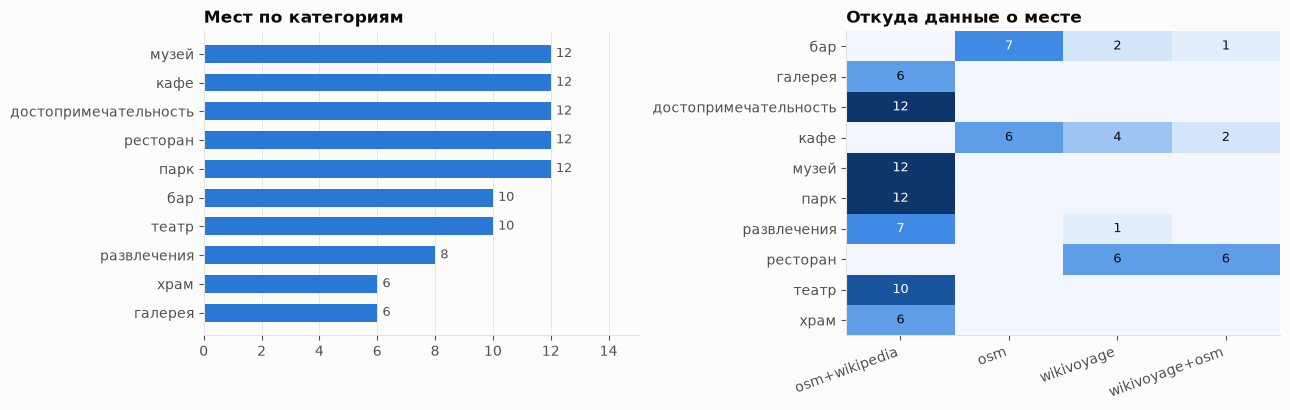

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
hbar(axes[0], places.category.value_counts(), 'Мест по категориям')
src = pd.crosstab(places.category, places.source)
src = src[src.sum().sort_values(ascending=False).index]
im = axes[1].imshow(src.values, cmap=SEQ, aspect='auto')
axes[1].set_xticks(range(src.shape[1]), src.columns, rotation=20, ha='right')
axes[1].set_yticks(range(src.shape[0]), src.index)
axes[1].grid(False)
for (i, j), v in np.ndenumerate(src.values):
    if v: axes[1].text(j, i, v, ha='center', va='center', fontsize=9, color='white' if v > src.values.max() * 0.55 else INK)
axes[1].set_title('Откуда данные о месте')
fig.tight_layout(); save(fig, '01_categories_sources'); plt.show()

Категории сбалансированы квотами (6–12 мест). Источники разделены почти идеально по типам мест: культура и прогулки идут из Википедии, еда из Wikivoyage и OSM.
Поэтому у общепита и у остальных мест **разное качество текста**. Это видно и на графике длины описаний:

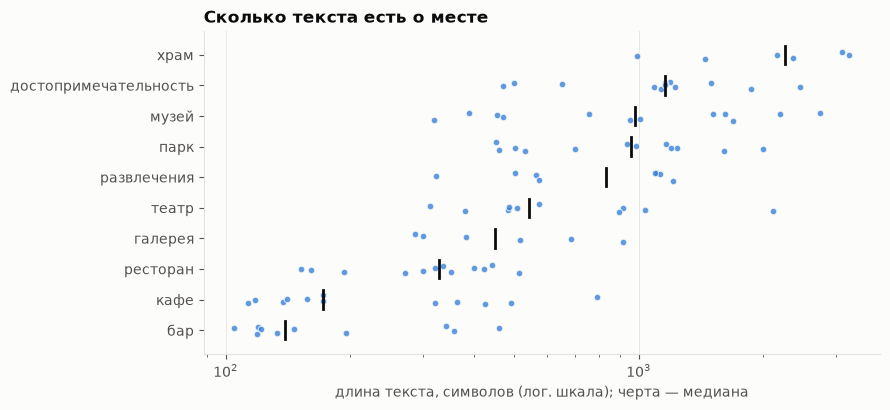

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.2))
order = places.groupby('category').text.apply(lambda s: s.str.len().median()).sort_values().index
for y, cat in enumerate(order):
    lens = places.loc[places.category == cat, 'text'].str.len()
    ax.scatter(lens, np.full(len(lens), y) + np.random.uniform(-0.15, 0.15, len(lens)), s=22, color=BLUE, alpha=0.75,
               edgecolor=SURFACE, linewidth=0.8)
    ax.plot([lens.median()] * 2, [y - 0.3, y + 0.3], color=INK, linewidth=2)
ax.set_yticks(range(len(order)), order); ax.grid(axis='y', visible=False)
ax.set_xscale('log'); ax.set_xlabel('длина текста, символов (лог. шкала); черта — медиана')
ax.set_title('Сколько текста есть о месте')
fig.tight_layout(); save(fig, '02_text_length'); plt.show()

У баров и части кафе текст состоит из одной-двух фраз, собранных из тегов OSM (~100 символов). У музеев и храмов это 1500+ символов из Википедии и Wikivoyage. Разница на порядок.

### 4.2 Распределение типов опыта, атмосфер и контекстов

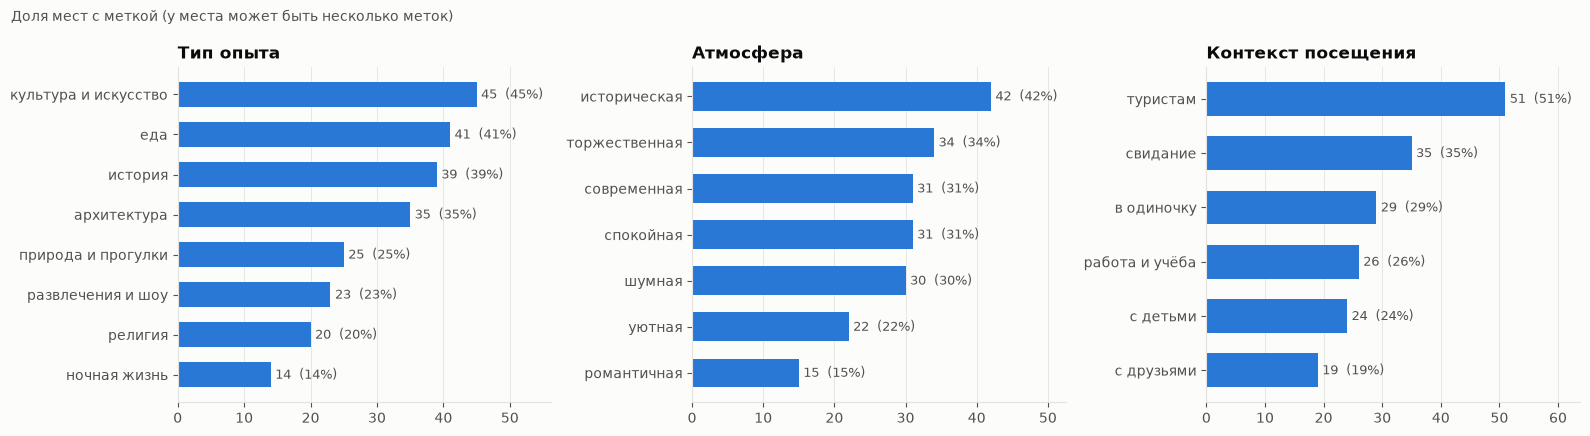

In [29]:
def label_counts(col, labels):
    return pd.Series({l: sum(l in v for v in places[col]) for l in labels})


fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
hbar(axes[0], label_counts('experience', EXPERIENCE), 'Тип опыта', total=len(places))
hbar(axes[1], label_counts('atmosphere', ATMOSPHERE), 'Атмосфера', total=len(places))
hbar(axes[2], label_counts('context', CONTEXT), 'Контекст посещения', total=len(places))
fig.suptitle('Доля мест с меткой (у места может быть несколько меток)', x=0.01, ha='left', color=INK2, fontsize=10)
fig.tight_layout(); save(fig, '03_label_distributions'); plt.show()

### 4.3 Как признаки связаны с категориями
Теплокарта показывает долю мест категории с данной меткой. По ней удобно проверять, насколько признаки «осмысленны»: в барах должны быть шумно и «с друзьями», в храмах торжественно.

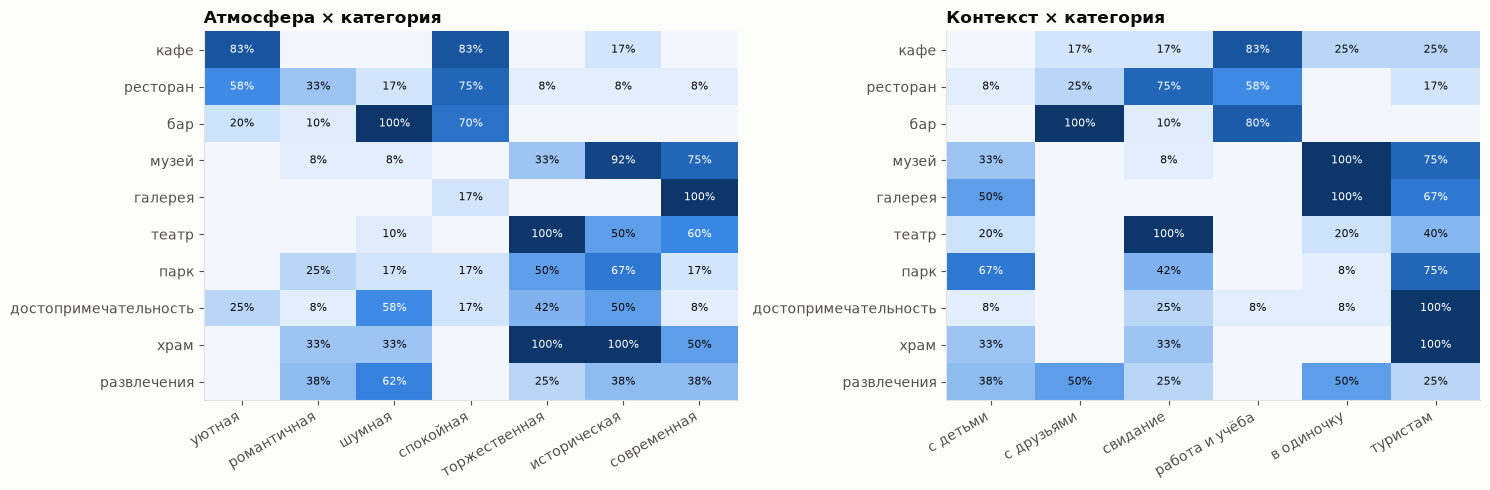

In [30]:
def share_matrix(col, labels):
    return pd.DataFrame({l: places.groupby('category')[col].apply(lambda s: np.mean([l in v for v in s])) for l in labels})


def heat(ax, m, title):
    ax.imshow(m.values, cmap=SEQ, vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=30, ha='right')
    ax.set_yticks(range(m.shape[0]), m.index)
    ax.grid(False); ax.set_title(title)
    for (i, j), v in np.ndenumerate(m.values):
        if v >= 0.05:
            ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white' if v > 0.55 else INK)


cat_order = list(QUOTAS)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
heat(axes[0], share_matrix('atmosphere', ATMOSPHERE).loc[cat_order], 'Атмосфера × категория')
heat(axes[1], share_matrix('context', CONTEXT).loc[cat_order], 'Контекст × категория')
fig.tight_layout(); save(fig, '04_heatmaps_atm_ctx'); plt.show()

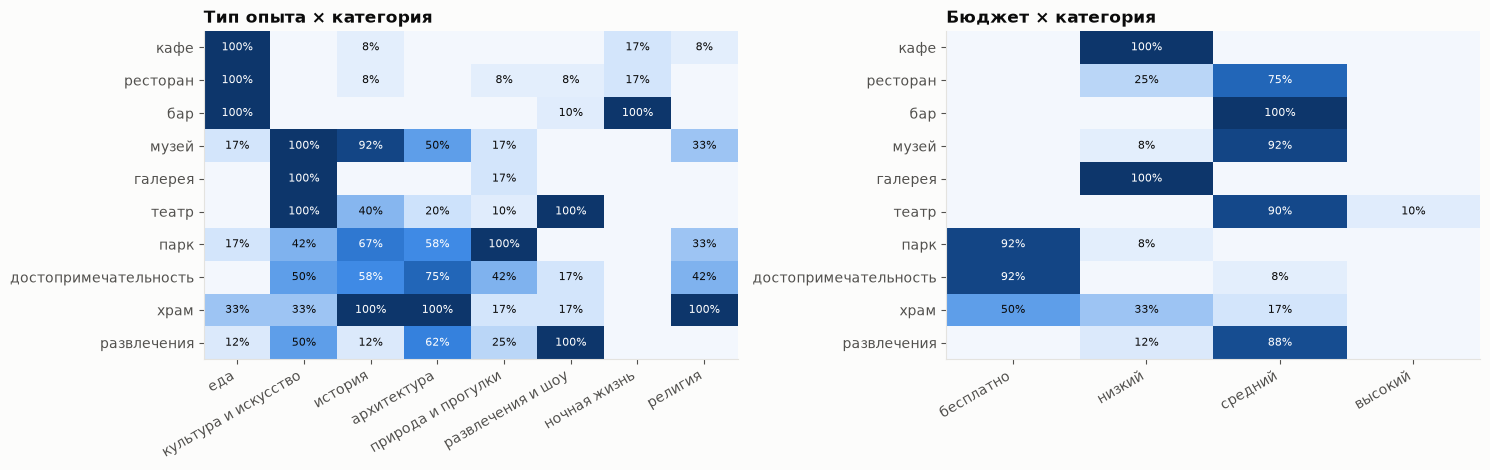

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
heat(axes[0], share_matrix('experience', EXPERIENCE).loc[cat_order], 'Тип опыта × категория')
bud_levels = ['бесплатно', 'низкий', 'средний', 'высокий']
bud = pd.crosstab(places.category, places.budget, normalize='index').reindex(index=cat_order, columns=bud_levels).fillna(0)
heat(axes[1], bud, 'Бюджет × категория')
fig.tight_layout(); save(fig, '05_heatmaps_exp_budget'); plt.show()

### 4.4 Время посещения, бюджет и откуда взялись значения
Важно видеть, какая часть структурных признаков **измерена** (часы работы, цена), а какая **подставлена по умолчанию** для категории.

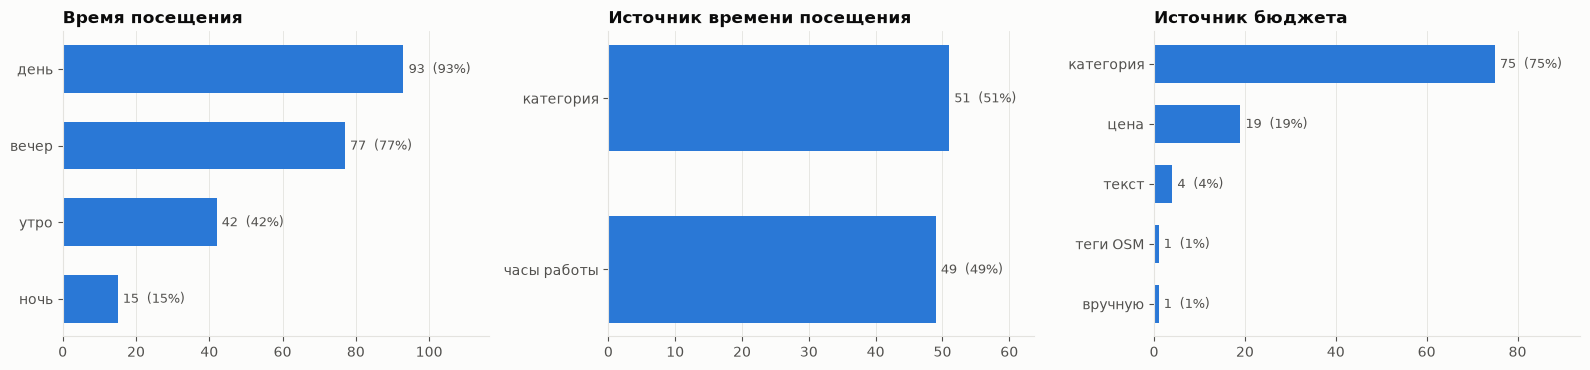

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
hbar(axes[0], label_counts('time_of_day', ['утро', 'день', 'вечер', 'ночь']), 'Время посещения', total=len(places))
hbar(axes[1], places.time_source.value_counts(), 'Источник времени посещения', total=len(places))
hbar(axes[2], places.budget_source.value_counts(), 'Источник бюджета', total=len(places))
fig.tight_layout(); save(fig, '06_time_budget_sources'); plt.show()

Бюджет у трёх четвертей мест подставлен по категории, это слабое место. Цены есть только в Wikivoyage и только у части мест (и они устаревают: в заметках встречаются цены 2014 года).
Время посещения лучше: примерно у половины мест оно разобрано из `opening_hours`.

### 4.5 Популярность
Просмотры статьи в Википедии за 12 месяцев распределены очень неравномерно: Кремль и Большой театр на два порядка популярнее галереи А3. Поэтому дальше используем `log`.

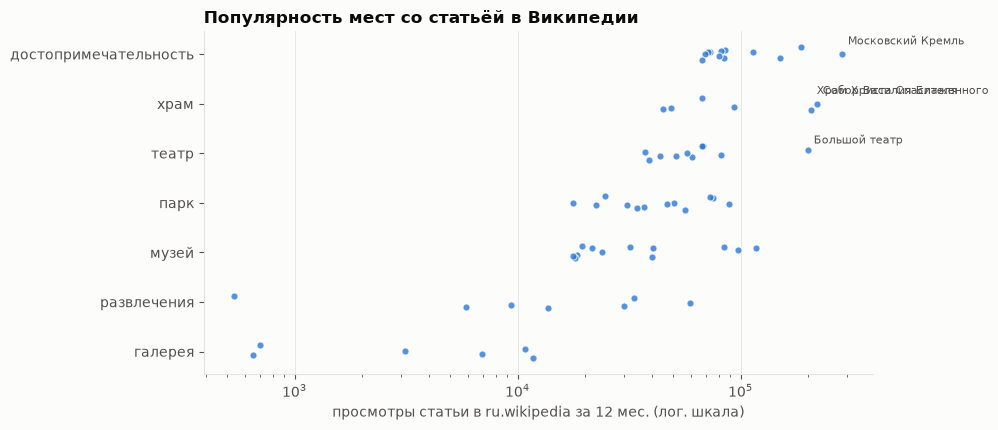

In [33]:
pv = places.dropna(subset=['pageviews_12m'])
fig, ax = plt.subplots(figsize=(10, 4.4))
order = pv.groupby('category').pageviews_12m.median().sort_values().index
for y, cat in enumerate(order):
    v = pv.loc[pv.category == cat, 'pageviews_12m']
    ax.scatter(v, np.full(len(v), y) + np.random.uniform(-0.15, 0.15, len(v)), s=26, color=BLUE, alpha=0.8,
               edgecolor=SURFACE, linewidth=0.8)
ax.set_yticks(range(len(order)), order); ax.grid(axis='y', visible=False)
ax.set_xscale('log'); ax.set_xlabel('просмотры статьи в ru.wikipedia за 12 мес. (лог. шкала)')
top = pv.nlargest(4, 'pageviews_12m')
for _, r in top.iterrows():
    ax.annotate(r['name'], (r.pageviews_12m, list(order).index(r.category)), xytext=(4, 7), textcoords='offset points',
                fontsize=8, color=INK2)
ax.set_title('Популярность мест со статьёй в Википедии')
fig.tight_layout(); save(fig, '07_popularity'); plt.show()

### 4.6 География
Датасет сильно сжат к центру: Кремль, Китай-город, Замоскворечье. Это следствие отбора по популярности и того, что Wikivoyage подробно описывает именно центр.

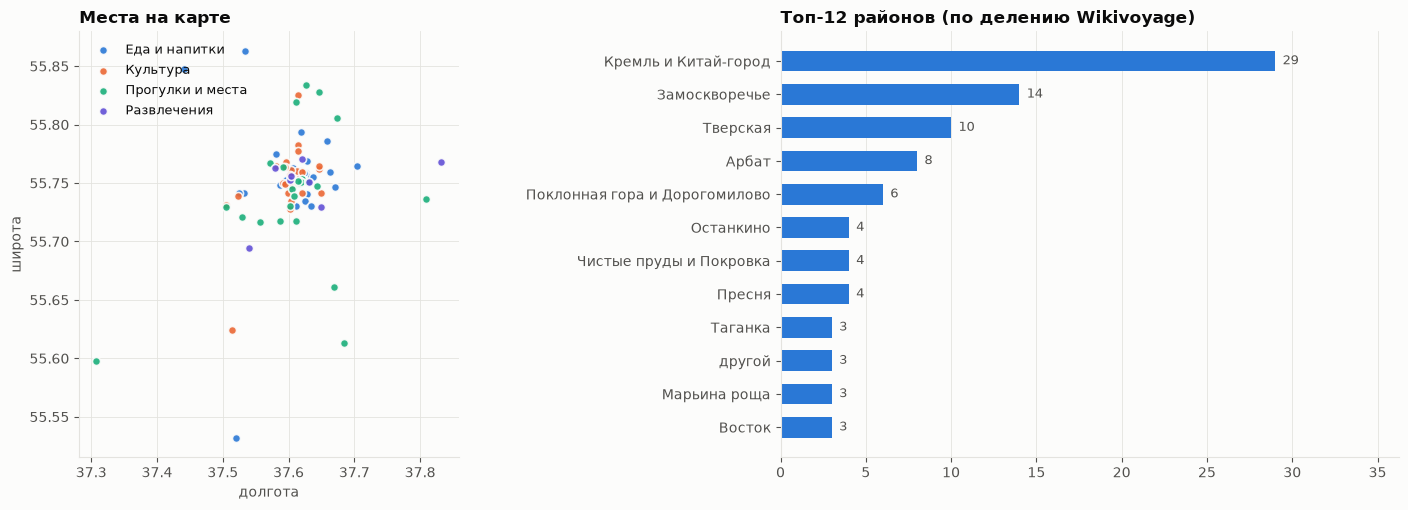

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
for m, color in MACRO_COLORS.items():
    d = places[places.macro == m]
    ax.scatter(d.lon, d.lat, s=34, color=color, label=m, edgecolor=SURFACE, linewidth=1.2, alpha=0.9)
ax.set_aspect(1 / np.cos(np.radians(55.75)))   # чтобы Москва не была «сплюснутой»
ax.set_xlabel('долгота'); ax.set_ylabel('широта'); ax.set_title('Места на карте')
ax.legend(frameon=False, loc='upper left', fontsize=9)
hbar(axes[1], places.district.value_counts().head(12), 'Топ-12 районов (по делению Wikivoyage)')
fig.tight_layout(); save(fig, '08_geo'); plt.show()

### 4.7 Семантическое пространство: проекция эмбеддингов
PCA от векторов e5 до 2D. Если эмбеддинги осмысленны, места одного типа должны стоять рядом.

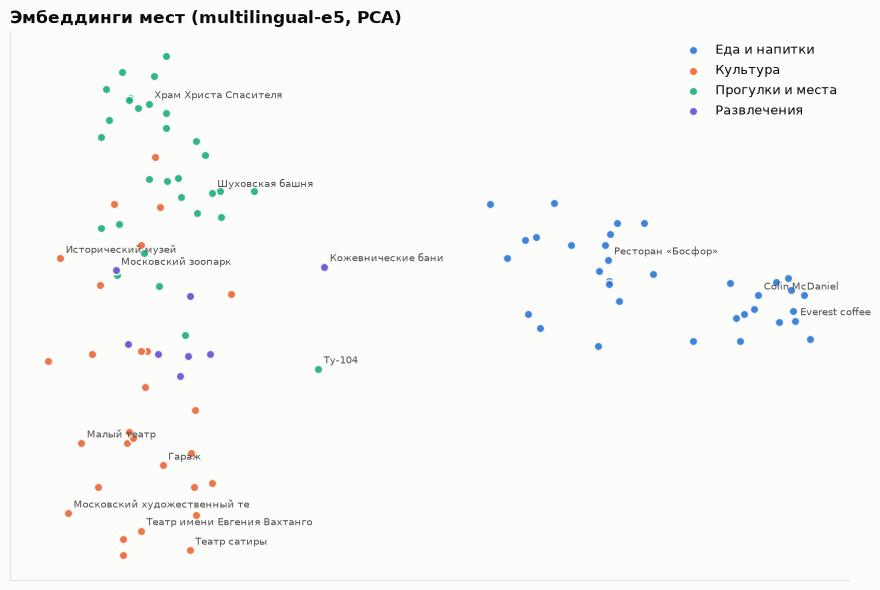

In [35]:
from sklearn.decomposition import PCA

xy = PCA(n_components=2, random_state=0).fit_transform(doc_emb)
fig, ax = plt.subplots(figsize=(9, 6))
for m, color in MACRO_COLORS.items():
    mask = (places.macro == m).values
    ax.scatter(xy[mask, 0], xy[mask, 1], s=38, color=color, label=m, edgecolor=SURFACE, linewidth=1.2, alpha=0.9)
for i in places.sample(14, random_state=2).index:
    ax.annotate(places.at[i, 'name'][:28], xy[i], xytext=(4, 4), textcoords='offset points', fontsize=7.5, color=INK2)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.set_title('Эмбеддинги мест (multilingual-e5, PCA)')
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); save(fig, '09_embeddings_pca'); plt.show()

### 4.8 Выводы EDA
- Категории сбалансированы квотами, а **признаки нет**: «туристам» и «историческая» встречаются очень часто (датасет смещён к центру и известным местам), «романтичная», «ночная жизнь» и «с друзьями» редко.
- EDA помогла найти ошибки. В первой версии метка «работа и учёба» стояла у всех баров с Wi-Fi. Правило «Wi-Fi → работа» я ограничил кафе и ресторанами, но на теплокарте у баров эта метка всё ещё ~80%: её теперь добавляет **эмбеддинг-модель**, потому что в шаблонном описании бара есть слова «Есть Wi-Fi». Zero-shot реагирует на слово, а не на смысл («бар с Wi-Fi» ≠ «место для работы»). Лечится запретом меток по категории или нормальной разметкой.
- Похожий артефакт: «современная» у половины храмов. Это правило по основе «современн» (Храм Христа Спасителя «воссоздан в современном виде») плюс hubness эмбеддингов.
- Теплокарты в целом «здравые»: бары шумные и «с друзьями», храмы торжественные и исторические, галереи современные. Значит, гибридное извлечение не выдаёт случайный шум.
- **Тексты общепита на порядок короче**, поэтому их мягкие признаки держатся в основном на правилах по категории и тегам.
- Бюджет у ~75% мест взят из значения по умолчанию для категории. Для реальной системы нужен источник цен (меню, средний чек из агрегаторов).
- На проекции эмбеддингов еда и культура хорошо разделяются, а «прогулки и места» перемешаны с культурой: в Википедии эти тексты похожи по стилю, все про историю и архитектуру.

## Задание 5. Эксперименты с поиском мест

Сравниваю четыре метода. Каждый следующий добавляет к предыдущему один источник информации:

| # | Метод | Что использует |
|---|---|---|
| A | **BM25** | лексический поиск по сырому тексту (название + описание + заметка), слова приводятся к основам стеммером Snowball |
| B | **Dense (raw)** | косинусная близость e5-эмбеддингов запроса (`query:`) и сырого текста (`passage:`) |
| C | **Dense (enriched)** | то же, но к тексту места дописаны извлечённые признаки: «Атмосфера: уютная. Подходит: для работы…» |
| D | **Hybrid** | C + разбор запроса на признаки (категория, атмосфера, контекст, бюджет, время, Wi-Fi, «рядом с …») и бонус за совпадение |

Запросов 10, они покрывают разные оси признаков. Релевантность я размечал вручную и **по всему датасету**: для каждого запроса заранее, до запуска поиска, выписал все подходящие места из 100 (их можно просмотреть целиком). Оценка бинарная: «подходит / не подходит».
Метрики: **P@5**, **nDCG@5**, **MRR**.

In [36]:
QUERIES = [
    'уютное кафе для работы с ноутбуком',
    'куда сходить с детьми в выходные',
    'романтическое место для свидания вечером',
    'шумный бар с крафтовым пивом для компании друзей',
    'бесплатная прогулка на природе',
    'современное искусство',
    'история России и древние соборы',
    'недорого поесть рядом с Красной площадью',
    'вечером послушать музыку или посмотреть спектакль',
    'место с красивым видом на город',
]

### 5.1 Индексы

In [37]:
import snowballstemmer
from rank_bm25 import BM25Okapi

stemmer = snowballstemmer.stemmer('russian')


def tokenize(s):
    return stemmer.stemWords(re.findall(r'[a-zа-я0-9]+', s.lower().replace('ё', 'е')))


bm25 = BM25Okapi([tokenize(t) for t in places.text])


def enriched_text(r):
    parts = [r.text,
             f'Категория: {r.category}.',
             f"Тип опыта: {', '.join(r.experience)}." if r.experience else '',
             f"Атмосфера: {', '.join(r.atmosphere)}." if r.atmosphere else '',
             f"Подходит: {', '.join(r.context)}." if r.context else '',
             f'Бюджет: {r.budget}.', f"Время: {', '.join(r.time_of_day)}.",
             'Есть Wi-Fi.' if r.has_wifi else '', 'Есть веранда.' if r.has_terrace else '']
    return ' '.join(p for p in parts if p)


places['text_enriched'] = places.apply(enriched_text, axis=1)
# признаки ставим В НАЧАЛО: e5 обрезает вход до 512 токенов, и у длинных статей хвост с признаками иначе потерялся бы
emb_raw = doc_emb
emb_enriched = E5.encode([f"passage: {t[len(r):]} {r}"[:2000] for t, r in zip(places.text_enriched, places.text)],
                         batch_size=16, normalize_embeddings=True, show_progress_bar=False)
print(places.text_enriched.iloc[80])

Спецбуфет № 1. кафе. Спецбуфет № 1. От американского дайнера здесь интерьер, а от советской столовой — всё остальное, в том числе и качество обслуживания. В меню пельмени, хачапури, котлеты и сосиски, со стен улыбается Леонид Ильич: в общем, это забавно, но не очень дёшево и не всегда вкусно. Судя по отзывам, иностранцам нравится, москвичи не столь оптимистичны. Категория: кафе. Тип опыта: еда. Атмосфера: уютная, спокойная. Подходит: в одиночку, туристам. Бюджет: низкий. Время: утро, день, вечер, ночь.


### 5.2 Разбор запроса на признаки (для метода D)
Это та же логика правил, что и при извлечении признаков, плюс несколько «запросных» слов («поесть», «музыку», «бесплатно»).
Отдельно добавлен **гео-якорь**: если в запросе упомянуто место из датасета («рядом с Красной площадью»), места ближе 1.5 км получают бонус.

In [38]:
QUERY_EXTRA = {
    'experience': {'еда': r'поесть|перекус|ужин|обед|кафе|ресторан', 'развлечения и шоу': r'музык|спектакл|концерт|шоу',
                   'природа и прогулки': r'природ|прогул|погулять', 'культура и искусство': r'искусств|музе|выставк',
                   'религия': r'собор|храм|церк'},
    'atmosphere': {'романтичная': r'красив\w* вид|вид на', 'шумная': r'шумн|весел'},
    'context': {'работа и учёба': r'работ|учеб|ноутбук', 'с друзьями': r'компани|друз',
                'свидание': r'свидан|девушк|романти', 'с детьми': r'дет|ребен|семь'},
}
QUERY_CATEGORY = {'кафе': r'кафе|кофейн|кофе', 'бар': r'\bбар|паб|пив|коктейл', 'ресторан': r'ресторан|ужин',
                  'музей': r'музе', 'галерея': r'галере|искусств', 'театр': r'театр|спектакл',
                  'парк': r'парк|природ|прогул', 'храм': r'храм|собор|церк'}


def parse_query(q):
    ql = q.lower().replace('ё', 'е')
    want = {g: {l for l, rx in LEXICON[g].items() if re.search(rx, ql)} |
               {l for l, rx in QUERY_EXTRA.get(g, {}).items() if re.search(rx, ql)} for g in GROUPS}
    want['category'] = {c for c, rx in QUERY_CATEGORY.items() if re.search(rx, ql)}
    want['budget'] = ({'бесплатно'} if re.search(r'бесплатн', ql) else
                      {'бесплатно', 'низкий'} if re.search(r'недорог|дешев|бюджетн', ql) else set())
    want['time'] = {t for t, rx in {'утро': r'утр|завтрак', 'вечер': r'вечер|ужин', 'ночь': r'ночь|ночн'}.items()
                    if re.search(rx, ql)}
    want['wifi'] = bool(re.search(r'ноутбук|wi-?fi|поработ|работ', ql))
    q_stems = set(tokenize(ql))
    want['anchor'] = next((i for i, n in places.name.items()                # «рядом с Красной площадью»
                           if len(tokenize(n)) >= 2 and set(tokenize(n)) <= q_stems), None)
    return want


for q in QUERIES[:3] + QUERIES[7:8]:
    w = parse_query(q)
    print(q, '→', {k: v for k, v in w.items() if v not in (set(), False, None)})

уютное кафе для работы с ноутбуком → {'experience': {'еда'}, 'atmosphere': {'уютная'}, 'context': {'работа и учёба'}, 'category': {'кафе'}, 'wifi': True}
куда сходить с детьми в выходные → {'context': {'с детьми'}}
романтическое место для свидания вечером → {'atmosphere': {'романтичная'}, 'context': {'свидание'}, 'time': {'вечер'}}
недорого поесть рядом с Красной площадью → {'experience': {'еда'}, 'context': {'туристам'}, 'budget': {'низкий', 'бесплатно'}, 'anchor': 7}


Бонус гибрида складывается из совпадений с признаками места. Веса я поставил вручную, исходя из того, что косинусная близость e5 у мест обычно лежит в узком диапазоне ~0.75–0.85, то есть 0.03 уже заметно меняет порядок.
По разметке веса не подбирал: она маленькая, и подгонка под неё сделала бы сравнение нечестным.

In [39]:
W_LABEL, W_CAT, W_BUDGET, W_TIME, W_WIFI, W_GEO = 0.03, 0.05, 0.04, 0.02, 0.04, 0.06


def feature_bonus(want):
    b = np.zeros(len(places))
    for g in GROUPS:
        for l in want[g]:
            b += W_LABEL * places[g].map(lambda v: l in v).values
    if want['category']:
        b += W_CAT * places.category.isin(want['category']).values
    if want['budget']:
        b += W_BUDGET * places.budget.isin(want['budget']).values - W_BUDGET * places.budget.eq('высокий').values
    for t in want['time']:
        b += W_TIME * places.time_of_day.map(lambda v: t in v).values
    if want['wifi']:
        b += W_WIFI * places.has_wifi.values
    if want['anchor'] is not None:
        a = places.loc[want['anchor']]
        dist = haversine_m(a.lat, a.lon, places.lat.values, places.lon.values)
        b += W_GEO * (dist < 1500)
        b[want['anchor']] -= 1.0          # сам ориентир в выдачу не нужен
    return b


def search(q, method, k=5):
    if method == 'BM25':
        s = bm25.get_scores(tokenize(q))
    else:
        qv = E5.encode([f'query: {q}'], normalize_embeddings=True)[0]
        s = (emb_raw if method == 'Dense raw' else emb_enriched) @ qv
        if method == 'Hybrid':
            s = s + feature_bonus(parse_query(q))
    top = np.argsort(-s)[:k]
    return places.iloc[top].assign(score=s[top])


METHODS = ['BM25', 'Dense raw', 'Dense enriched', 'Hybrid']
results = {(q, m): search(q, m) for q in QUERIES for m in METHODS}

### 5.3 Выдача по запросам
Для каждого запроса показываю top-5 всех методов рядом. ✓ — место есть в моём списке релевантных для запроса.

In [40]:
RELEVANT = {
    'уютное кафе для работы с ноутбуком': {
        'Krispy Kreme Doughnuts', 'Пушкарёв', 'Coffeepie', 'Everest coffee', 'Boring Coffee', 'Villa Pasta на Пятницкой',
        'Кафе «Шоколадница»'},
    'куда сходить с детьми в выходные': {
        'Московский зоопарк', 'Большой Московский Государственный цирк', 'Московский цирк Никулина',
        'Палеонтологический музей имени Ю.А. Орлова РАН', 'Парк Горького', 'парк Сокольники', 'Музей-заповедник «Коломенское»',
        'Дворцово-парковый ансамбль «Царицыно»', 'Выставка достижений народного хозяйства', 'Музей-панорама «Бородинская битва»',
        'Музей-заповедник Кусково', 'Парк Победы', 'Музей Победы', 'Нескучный сад'},
    'романтическое место для свидания вечером': {
        'Парк Воробьёвы горы', 'Патриаршие пруды', 'Нескучный сад', 'парк «Зарядье»', '"Квартира 44" на Малой Якиманке',
        'Ресторан Mandarin combustible', 'Большой театр', 'Парк Горького', 'Romanov bar',
        'Александровский сад'},
    'шумный бар с крафтовым пивом для компании друзей': {
        'Craft Republic', 'Крафт будка', 'Bad.Bro.Bar', 'Sporco', 'Colin McDaniel', 'Жигули', 'Symposy', '1980'},
    'бесплатная прогулка на природе': {
        'Нескучный сад', 'Парк Воробьёвы горы', 'Парк Горького', 'парк Сокольники', 'Музей-заповедник «Коломенское»',
        'Дворцово-парковый ансамбль «Царицыно»', 'Парк Победы', 'Патриаршие пруды', 'Александровский сад', 'парк «Зарядье»',
        'Выставка достижений народного хозяйства'},
    'современное искусство': {
        'Гараж', 'Мультимедиа Арт Музей', 'Государственный центр современного искусства', 'Центральный дом художника', 'А3'},
    'история России и древние соборы': {
        'Собор Успения Пресвятой Богородицы', 'Собор Михаила Архангела', 'Собор Василия Блаженного',
        'Церковь Иоанна Лествичника', 'Исторический музей', 'Московский Кремль', 'Храм Христа Спасителя',
        'Музей-заповедник «Коломенское»', 'Красная площадь', 'Оружейная палата'},
    'недорого поесть рядом с Красной площадью': {
        'Столовая № 57', 'Кафе «Монастырская выпечка»', 'Спецбуфет № 1', 'Krispy Kreme Doughnuts', 'Вареничная № 1',
        'Кафе «Сорока»'},
    'вечером послушать музыку или посмотреть спектакль': {
        'Большой театр', 'Малый театр', 'Московский художественный театр им. А. П. Чехова', 'МХАТ им. Горького', 'Современник',
        'Театр имени Евгения Вахтангова', 'Театр сатиры', 'Театр Российской армии', 'Театр им. Вл. Маяковского',
        'Московский театр Олега Табакова', 'Большой зал Консерватории', 'Концертный зал «Зарядье»', '"Квартира 44" на Малой Якиманке'},
    'место с красивым видом на город': {
        'Парк Воробьёвы горы', 'Останкинская телевизионная башня', 'парк «Зарядье»', 'Церковь Иоанна Лествичника'},
}
assert all(n in set(places.name) for s in RELEVANT.values() for n in s), \
    [n for s in RELEVANT.values() for n in s if n not in set(places.name)]


def show_query(q):
    cols = {}
    for m in METHODS:
        r = results[(q, m)]
        cols[m] = [('✓ ' if n in RELEVANT[q] else '✗ ') + f'{n[:34]} [{c}]' for n, c in zip(r.name, r.category)]
    return pd.DataFrame(cols, index=range(1, 6))


for q in QUERIES:
    print(f'\n### {q}')
    print(show_query(q).to_string())


### уютное кафе для работы с ноутбуком
                              BM25                Dense raw           Dense enriched                   Hybrid
1  ✓ Krispy Kreme Doughnuts [кафе]       ✓ Coffeepie [кафе]   ✓ Boring Coffee [кафе]   ✓ Boring Coffee [кафе]
2           ✓ Boring Coffee [кафе]   ✓ Boring Coffee [кафе]         ✗ Наф-Наф [кафе]         ✗ Наф-Наф [кафе]
3                 ✗ Наф-Наф [кафе]         ✗ Наф-Наф [кафе]       ✓ Coffeepie [кафе]  ✓ Everest coffee [кафе]
4      ✓ Кафе «Шоколадница» [кафе]  ✓ Everest coffee [кафе]  ✓ Everest coffee [кафе]        ✓ Пушкарёв [кафе]
5          ✓ Everest coffee [кафе]      ✗ Крафт будка [бар]        ✓ Пушкарёв [кафе]        ✗ Pho Ngon [кафе]

### куда сходить с детьми в выходные
                                          BM25                                Dense raw                         Dense enriched                                   Hybrid
1             ✗ Ресторан «Годуновъ» [ресторан]            ✗ Ресторан "Сунжа" [ресторан]       

### 5.4 Метрики

In [41]:
def metrics(q, m, k=5):
    rel = [n in RELEVANT[q] for n in results[(q, m)].name[:k]]
    dcg = sum(r / np.log2(i + 2) for i, r in enumerate(rel))
    idcg = sum(1 / np.log2(i + 2) for i in range(min(k, len(RELEVANT[q]))))
    mrr = next((1 / (i + 1) for i, r in enumerate(rel) if r), 0.0)
    return {'P@5': np.mean(rel), 'nDCG@5': dcg / idcg, 'MRR': mrr}


per_query = pd.DataFrame([{'query': q, 'method': m, **metrics(q, m)} for q in QUERIES for m in METHODS])
summary = per_query.groupby('method')[['P@5', 'nDCG@5', 'MRR']].mean().loc[METHODS]
summary.round(3)

,P@5,nDCG@5,MRR
method,,,
BM25,0.42,0.437,0.595
Dense raw,0.56,0.584,0.720
Dense enriched,0.64,0.667,0.853
Hybrid,0.74,0.770,0.933


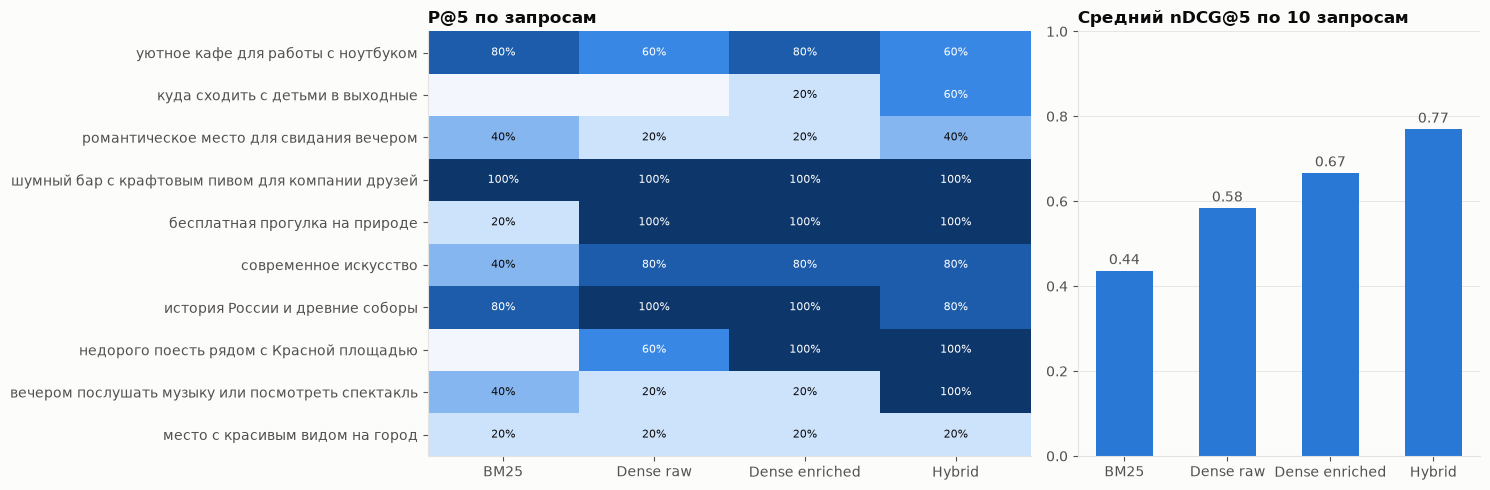

In [42]:
p5 = per_query.pivot(index='query', columns='method', values='P@5').loc[QUERIES, METHODS]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.5, 1]})
heat(axes[0], p5, 'P@5 по запросам')
axes[0].set_xticks(range(len(METHODS)), METHODS, rotation=0, ha='center')
ax = axes[1]
x = np.arange(len(METHODS))
ax.bar(x, summary['nDCG@5'], color=BLUE, width=0.55)
for i, v in enumerate(summary['nDCG@5']):
    ax.text(i, v + 0.015, f'{v:.2f}', ha='center', fontsize=10, color=INK2)
ax.set_xticks(x, METHODS); ax.set_ylim(0, 1); ax.grid(axis='x', visible=False)
ax.set_title('Средний nDCG@5 по 10 запросам')
fig.tight_layout(); save(fig, '10_search_metrics'); plt.show()

### 5.5 Вклад отдельных признаков (ablation)
Выключаем по одной группе бонусов в гибриде и смотрим, сколько теряем в nDCG@5.

In [43]:
def run_with_weights(**override):
    global W_LABEL, W_CAT, W_BUDGET, W_TIME, W_WIFI, W_GEO
    saved = (W_LABEL, W_CAT, W_BUDGET, W_TIME, W_WIFI, W_GEO)
    for k, v in override.items():
        globals()[k] = v
    try:
        scores = []
        for q in QUERIES:
            results[(q, 'tmp')] = search(q, 'Hybrid')
            scores.append(metrics(q, 'tmp')['nDCG@5'])
        return np.mean(scores)
    finally:
        W_LABEL, W_CAT, W_BUDGET, W_TIME, W_WIFI, W_GEO = saved


base = summary.loc['Hybrid', 'nDCG@5']
ablation = pd.Series({
    'без меток (опыт/атмосфера/контекст)': run_with_weights(W_LABEL=0),
    'без категории': run_with_weights(W_CAT=0),
    'без бюджета': run_with_weights(W_BUDGET=0),
    'без времени': run_with_weights(W_TIME=0),
    'без Wi-Fi': run_with_weights(W_WIFI=0),
    'без гео-якоря': run_with_weights(W_GEO=0),
}).to_frame('nDCG@5')
ablation['Δ к полному гибриду'] = ablation['nDCG@5'] - base
ablation.round(3)

,nDCG@5,Δ к полному гибриду
без меток (опыт/атмосфера/контекст),0.724,-0.046
без категории,0.783,0.013
без бюджета,0.740,-0.030
без времени,0.770,0.000
без Wi-Fi,0.783,0.013
без гео-якоря,0.770,0.000


### 5.6 Сохраняем сравнительную таблицу
`results/search_comparison.xlsx` (листы: сводка, по запросам, выдача, абляция) и `results/search_comparison.csv`.

In [44]:
top5 = pd.DataFrame([{'query': q, 'method': m, 'rank': i + 1, 'name': n, 'category': c, 'relevant': n in RELEVANT[q]}
                     for q in QUERIES for m in METHODS
                     for i, (n, c) in enumerate(zip(results[(q, m)].name, results[(q, m)].category))])
per_query.round(3).to_csv(RES / 'search_comparison.csv', index=False)
with pd.ExcelWriter(RES / 'search_comparison.xlsx') as xw:
    summary.round(3).to_excel(xw, sheet_name='summary')
    per_query.round(3).to_excel(xw, sheet_name='per_query', index=False)
    top5.to_excel(xw, sheet_name='top5', index=False)
    ablation.round(3).to_excel(xw, sheet_name='ablation')
print('сохранено в', RES)

сохранено в results


### 5.7 Насколько результаты соответствуют ожиданиям

| Метод | P@5 | nDCG@5 | MRR |
|---|---|---|---|
| BM25 | 0.42 | 0.44 | 0.60 |
| Dense raw (e5) | 0.56 | 0.58 | 0.72 |
| Dense enriched (e5 + признаки в тексте) | 0.64 | 0.67 | 0.85 |
| **Hybrid** (enriched + бонусы за признаки) | **0.74** | **0.77** | **0.93** |

**Где хорошо.** Запросы, которые прямо ложатся на категорию или на явные слова: «шумный бар с крафтовым пивом» (P@5 = 1 у всех методов), «бесплатная прогулка на природе», «современное искусство», «история и древние соборы». Здесь даже BM25 неплох, а dense-поиск почти идеален.

**Где плохо и почему:**
- *«куда сходить с детьми»*: BM25 и dense по сырому тексту выдают рестораны и бары. В тексте мест про детей почти ничего нет, а вопросительная форма запроса сбивает лексический поиск. Помогает только признак `context = с детьми` в гибриде (0 → 0.6). При этом зоопарк и цирки в top-5 не попали: у них в описании ничего «детского», а признак `с детьми` гибрид поставил и Патриаршим прудам, и ЦДХ.
- *«вечером послушать музыку или посмотреть спектакль»*: dense-методы уходят в бары (видимо, «вечер + музыка» ≈ бар). Гибрид с бонусами за `развлечения и шоу` + `вечер` + категорию «театр» даёт P@5 = 1.0.
- *«место с красивым видом на город»*: провал у всех (P@5 = 0.2). В схеме **нет признака «панорамный вид / смотровая площадка»**, а в текстах об Останкинской башне смотровая упоминается не во вступлении. Нужен отдельный признак из тегов OSM (`tourism=viewpoint`, высота здания).
- *«романтическое место для свидания»*: слабо (0.4). Метку «романтичная» правила ставят редко (15% мест), а эмбеддинги путают её с «торжественной».
- *«уютное кафе для работы»*: гибрид немного хуже enriched-поиска. Бонус за Wi-Fi поднимает «Наф-Наф» и «Pho Ngon», где Wi-Fi есть, но для работы они не подходят. Признак Wi-Fi полезен как фильтр, но не как замена «тишины» и «розеток».

### 5.8 Какие признаки помогли
- **Сам факт обогащения текста** признаками (+0.08 nDCG к dense raw): у кафе и баров текст короткий, и строка «Подходит: работа и учёба, Wi-Fi» даёт модели то, чего нет в исходном описании.
- **Метки experience / atmosphere / context** дают наибольший вклад в гибриде: без них nDCG падает на 0.046.
- **Бюджет** (−0.03 без него): «недорого поесть» и «бесплатная прогулка».
- **Категория и Wi-Fi** в абляции немного *мешают* (+0.013 без них): бонус за категорию выталкивает «не те» кафе, а Wi-Fi описан выше. Веса я не подбирал, это первые кандидаты на настройку.
- **Время** и **гео-якорь** на этих 10 запросах ничего не изменили: dense-поиск и так находит кафе у Красной площади, а время почти везде совпадает с категорией. Гео-якорь станет важен на датасете, где места не сосредоточены в центре.

*Оговорка:* 10 запросов и моя разметка релевантности — это маленькая и субъективная оценка. Разница между dense enriched и hybrid (0.67 → 0.77) держится в основном на 3–4 запросах.

## Итоговые выводы

### Что сделано
1. Собран датасет из **100 мест Москвы** в 10 категориях (квоты 6–12) из **OSM, Википедии, Wikidata и Wikivoyage**. Все ответы API закешированы, пайплайн воспроизводим.
2. Предложена схема из **8 групп признаков**: тип опыта, атмосфера, контекст, бюджет, время, популярность, помещение/улица, длительность визита, плюс флаги удобств.
3. Извлечение признаков: структурные берутся **правилами по полям** (часы, цена, теги, просмотры), «мягкие» **гибридом правил и zero-shot на эмбеддингах e5**. Сравнение на ручной разметке 30 мест: гибрид macro F1 = **0.71**, правила 0.70, e5 zero-shot 0.57 (с центрированием) / 0.49 (без), NLI 0.36.
4. EDA показала перекосы датасета: центр города, туристические места, короткие тексты у общепита, бюджет в основном по умолчанию.
5. Семантический поиск: гибрид «эмбеддинги + признаки» лучше BM25 почти в 2 раза по nDCG@5 (0.77 против 0.44).

### Выводы для задачи рекомендаций мест
- **Чистый эмбеддинг-поиск — хорошая база, но недостаточная** для разговорных запросов «с кем / когда / сколько стоит». Структурированные признаки дают заметный прирост, и их удобно использовать как фильтры в диалоге («а подешевле?»).
- **Описание места ≠ опыт посещения.** Википедия рассказывает про историю здания, но ничего не говорит о том, шумно ли там и можно ли с детьми. Для атмосферы и контекста нужны **отзывы**. Это главный источник, которого здесь не хватает.
- **Zero-shot без калибровки опасен:** hubness эмбеддингов и плохая калибровка NLI дают «современную» Царь-пушку. Простое центрирование оценок по меткам заметно помогает и ничего не стоит.
- Правила по тегам OSM и категориям — дешёвый и сильный бейзлайн. Его стоит оставлять как слой в любой системе: он объясним, и его легко чинить.

### Ограничения и проблемы
- **Нет настоящих отзывов**: API Google/2ГИС/Яндекс/TripAdvisor закрыты или платные, парсинг запрещён. Заметки Wikivoyage есть лишь у ~40% мест, и часть из них устарела (цены 2014 года, закрытые заведения).
- **Смещения отбора:** топ по просмотрам Википедии = известные места в центре. Общепит отобран по полноте тегов OSM, а не по качеству. Сетевые заведения отсекаются эвристикой и проходят не всегда (Krispy Kreme, «Наф-Наф»).
- **Ошибки связывания источников:** тег `wikidata` в OSM иногда указывает на «предмет» объекта (музей 1812 года → статья о войне). Такие связи я отфильтровал эвристиками, но не полностью, и одно место из Wikivoyage («Кожевнические бани») попало в «развлечения» по ключевому слову, хотя это скорее памятник архитектуры.
- **Оценка маленькая и субъективная:** 30 размеченных мест, 10 запросов, всё размечено одним человеком (мной). Словари правил я писал, уже видя тексты размеченных мест, так что оценка правил и гибрида оптимистична.
- Бюджет у ~75% мест — значение по умолчанию для категории. Признака «панорамный вид» нет, и это видно по провалу соответствующего запроса.

### Что бы я сделал дальше
1. Добавить отзывы (Google Places API, до 5 на место, или датасеты отзывов) и извлекать атмосферу/контекст в первую очередь из них.
2. Попробовать LLM-извлечение признаков в JSON и сравнить с гибридом на **отложенной** разметке, большей по объёму и от нескольких разметчиков.
3. Добавить признаки «вид/панорама», «сезонность», «нужна запись/билеты» и цены из меню.
4. Подобрать веса гибрида на отдельном наборе запросов (или обучить learning-to-rank) и добавить reranker (cross-encoder).